# Memprediksi Status Jutawan dari Kebiasaan Finansial

**Mata kuliah**: Pembelajaran Mesin Mendalam, FMIPA UGM · **Dataset**: Millionaire Habits (100.000 individu sintetis, 274 kolom) · **Target**: `millionaire_status` (klasifikasi biner) · **Tools**: Python, PyTorch, Scikit-Learn, Pandas, Matplotlib, Seaborn

| Bagian | Isi |
|:--|:--|
| 1 | Identitas kelompok |
| 2 | Problem statement dan leakage |
| 3 | Setup |
| 4 | EDA |
| 5 | Audit leakage dan empat set fitur |
| 6 | Split data dan preprocessing |
| 7 | Arsitektur |
| 8 | Fungsi pelatihan dan evaluasi |
| 9 | Eksperimen 1: benchmark 5-fold CV |
| 10 | Eksperimen 2: tuning champion |
| 11 | Eksperimen 3: ablation |
| 12 | Evaluasi akhir di test set |
| 13 | Permutation importance |
| 14 | Fungsi inferensi |
| 14b | Tambahan di luar silabus: Tabular ResNet |
| 15 | Kesimpulan dan keterbatasan |
| 16 | Repositori dan referensi |

---
## 2. Problem Statement

**Pertanyaan riset:** apakah kebiasaan seseorang (menabung, berinvestasi, produktivitas, gaya hidup, psikologi keuangan) bisa memprediksi status jutawan, dan kebiasaan apa yang paling membedakan?

Targetnya dihitung dari rumus berikut:

$$\text{millionaire\_status}=\mathbb{1}\left[\text{net\_worth}\ge 1.000.000\right],\qquad \text{net\_worth}=\text{total\_assets}-\text{total\_liabilities}$$

**Kenapa leakage jadi masalah utama.** Kalau model diberi fitur yang sudah memuat jawaban, akurasinya tinggi tapi tidak berarti apa-apa. Di dataset ini ada tiga level:

1. **Langsung:** `net_worth`, `net_worth_log`, `net_worth_percentile`, `wealth_bracket`, `wealth_category`, `multi_millionaire_status`, `financial_independence_status`.
2. **Neraca:** `total_assets`, `total_liabilities`, `total_debt` (identik dengan `total_liabilities`), dan semua komponen aset/utang seperti `stocks_value`, `investment_assets`, `mortgage_debt`.
3. **Arus uang:** pendapatan, tabungan, investasi bulanan, pengeluaran. Ini bukan leakage murni, tapi lebih ke hasil daripada kebiasaan, jadi kami siapkan set fitur tanpa arus uang (Set C/D) sebagai pembanding.

Semua klaim ini dibuktikan dari data di Bagian 5.

---
## 3. Setup

In [1]:
import os, time, random, json, copy, warnings
from pathlib import Path
from types import SimpleNamespace

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

import torch
import torch.nn as nn
import torch.nn.functional as F

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.calibration import calibration_curve
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, brier_score_loss,
                             confusion_matrix, classification_report, roc_curve,
                             precision_recall_curve)
import joblib

warnings.filterwarnings("ignore")

# ---------- Konfigurasi global (satu tempat untuk semua eksperimen) ----------
SEED        = 42
BATCH_SIZE  = 512
MAX_EPOCHS  = 30      # batas atas; early stopping biasanya berhenti lebih awal
PATIENCE    = 6       # early stopping pada val_loss
LR, WD      = 1e-3, 1e-4
CV_FOLDS    = 5
N_SEEDS     = 5       # untuk uji stabilitas model akhir

def seed_everything(seed=SEED):
    random.seed(seed); np.random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    torch.manual_seed(seed)

seed_everything()
torch.set_num_threads(max(1, os.cpu_count() or 1))
DEVICE = "cpu"   # data tabular kecil: CPU sudah cukup & deterministik

FIG_DIR, OUT_DIR = Path("figures"), Path("outputs")
FIG_DIR.mkdir(exist_ok=True); OUT_DIR.mkdir(exist_ok=True)

# ---------- Tema visual konsisten ----------
C = dict(blue="#2563EB", orange="#F59E0B", green="#16A34A", red="#DC2626",
         purple="#7C3AED", gray="#6B7280", teal="#0D9488")
MODEL_COLORS = {"Baseline MLP": C["blue"], "Deep Regularized MLP": C["orange"], "Wide Regularized MLP": C["green"]}
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 12,
                     "axes.spines.top": False, "axes.spines.right": False})

def savefig(name):
    plt.tight_layout(); plt.savefig(FIG_DIR / f"{name}.png", dpi=200, bbox_inches="tight")

print(f"PyTorch {torch.__version__} | device: {DEVICE} | threads: {torch.get_num_threads()} | seed: {SEED}")


PyTorch 2.13.0+cu130 | device: cpu | threads: 12 | seed: 42


---
## 4. EDA
Memuat data, mengecek ukuran, distribusi target, dan missing value.

In [2]:
CANDIDATE_PATHS = ["Millionaire_Habits_Dataset.csv", "datasets/Millionaire_Habits_Dataset.csv",
                   "../Millionaire_Habits_Dataset.csv", "/mnt/user-data/uploads/Millionaire_Habits_Dataset.csv"]
data_path = next((p for p in CANDIDATE_PATHS if os.path.exists(p)), None)
if data_path is None:
    raise FileNotFoundError("Letakkan Millionaire_Habits_Dataset.csv di folder yang sama dengan notebook.")

t0 = time.time()
df = pd.read_csv(data_path)
TARGET = "millionaire_status"
y_all = df[TARGET].values.astype(np.float32)
print(f"File     : {data_path}")
print(f"Dimensi  : {df.shape[0]:,} baris × {df.shape[1]} kolom  (dibaca {time.time()-t0:.1f} dtk)")
print(f"Numerik  : {df.select_dtypes('number').shape[1]} kolom | Non-numerik: {df.select_dtypes(exclude='number').shape[1]} kolom")

File     : datasets/Millionaire_Habits_Dataset.csv
Dimensi  : 100,000 baris × 274 kolom  (dibaca 4.9 dtk)
Numerik  : 229 kolom | Non-numerik: 45 kolom


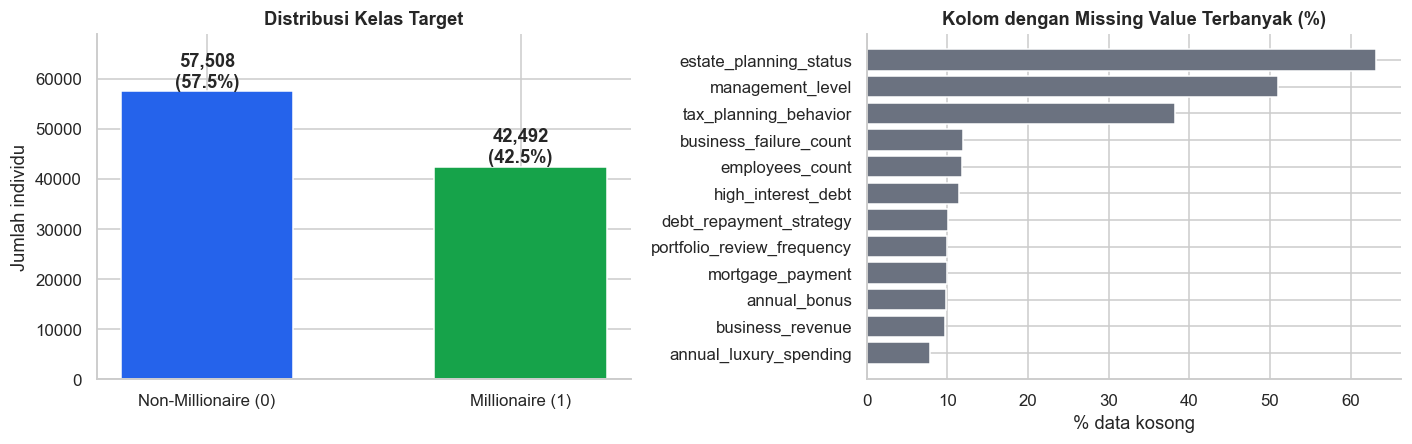

Kolom yang punya missing value: 34 dari 274
Kelas cukup seimbang (rasio ≈ 57:43) → accuracy valid dipakai, tetap dilaporkan bersama F1, ROC-AUC, PR-AUC.


In [3]:
# Distribusi kelas & kolom dengan missing value
counts = df[TARGET].value_counts().sort_index()
miss = (df.isna().mean() * 100).sort_values(ascending=False)
miss = miss[miss > 0].head(12)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
bars = ax[0].bar(["Non-Millionaire (0)", "Millionaire (1)"], counts.values, color=[C["blue"], C["green"]], width=.55)
for b, v in zip(bars, counts.values):
    ax[0].text(b.get_x()+b.get_width()/2, v+800, f"{v:,}\n({v/len(df)*100:.1f}%)", ha="center", fontweight="bold")
ax[0].set_title("Distribusi Kelas Target"); ax[0].set_ylabel("Jumlah individu"); ax[0].set_ylim(0, counts.max()*1.2)

ax[1].barh(miss.index[::-1], miss.values[::-1], color=C["gray"])
ax[1].set_title("Kolom dengan Missing Value Terbanyak (%)"); ax[1].set_xlabel("% data kosong")
savefig("01_target_dan_missing"); plt.show()
print(f"Kolom yang punya missing value: {int((df.isna().sum()>0).sum())} dari {df.shape[1]}")
print("Kelas cukup seimbang (rasio ≈ 57:43) → accuracy valid dipakai, tetap dilaporkan bersama F1, ROC-AUC, PR-AUC.")

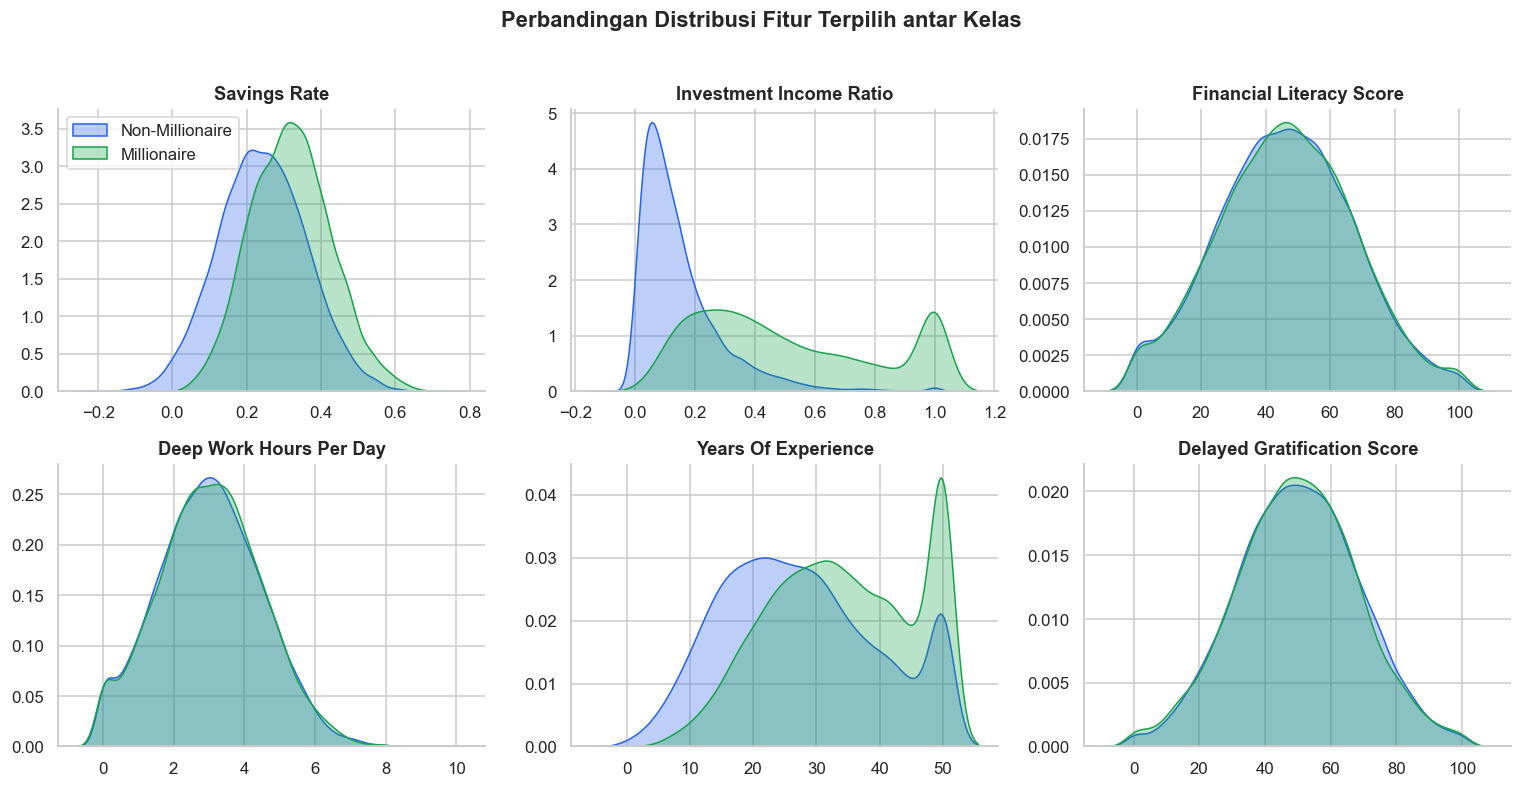

In [4]:
# Distribusi beberapa fitur 'kebiasaan' berdasarkan kelas
show = ["savings_rate", "investment_income_ratio", "financial_literacy_score",
        "deep_work_hours_per_day", "years_of_experience", "delayed_gratification_score"]
samp = df.sample(20000, random_state=SEED)
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, col in zip(axes.ravel(), show):
    for cls, color, lbl in [(0, C["blue"], "Non-Millionaire"), (1, C["green"], "Millionaire")]:
        sns.kdeplot(samp.loc[samp[TARGET]==cls, col].dropna(), ax=ax, color=color, fill=True, alpha=.30, label=lbl, common_norm=False)
    ax.set_title(col.replace("_", " ").title()); ax.set_xlabel(""); ax.set_ylabel("")
axes[0, 0].legend()
fig.suptitle("Perbandingan Distribusi Fitur Terpilih antar Kelas", fontweight="bold", y=1.02)
savefig("02_distribusi_fitur"); plt.show()

---
## 5. Audit Leakage dan Set Fitur

Sebelum membuang kolom, hubungan matematisnya kami cek langsung dari data, tidak hanya dari nama kolom.

In [5]:
BAL_ASSETS = ["cash_savings", "checking_savings", "investment_assets", "stocks_value", "bonds_value",
              "real_estate_value", "retirement_accounts", "business_equity", "alternative_assets",
              "vehicle_assets", "other_assets"]
BAL_LIAB   = ["mortgage_debt", "student_debt", "credit_card_debt", "business_debt", "other_debt"]

checks = {
 "net_worth ≡ total_assets − total_liabilities (selisih maks.)":  float((df.total_assets - df.total_liabilities - df.net_worth).abs().max()),
 "millionaire_status ≡ [net_worth ≥ 1 juta] (kecocokan)":         float(((df.net_worth >= 1e6).astype(int) == df[TARGET]).mean()),
 "total_liabilities ≡ Σ komponen utang (selisih maks.)":           float((df[BAL_LIAB].sum(axis=1) - df.total_liabilities).abs().max()),
 "total_debt ≡ total_liabilities (selisih maks.)":                 float((df.total_debt - df.total_liabilities).abs().max()),
 "total_assets vs Σ 11 komponen aset (selisih median)":            float((df[BAL_ASSETS].sum(axis=1) - df.total_assets).abs().median()),
}
display(pd.Series(checks, name="nilai").to_frame().style.format("{:,.4f}"))
print("Catatan: total_assets TIDAK sama persis dengan jumlah 11 komponen yang tersedia (ada komponen tak terlihat),")
print("namun total_debt identik dengan total_liabilities — sehingga membuang total_liabilities saja TIDAK cukup.")

,nilai
net_worth ≡ total_assets − total_liabilities (selisih maks.),0.0100
millionaire_status ≡ [net_worth ≥ 1 juta] (kecocokan),1.0000
total_liabilities ≡ Σ komponen utang (selisih maks.),0.0200
total_debt ≡ total_liabilities (selisih maks.),0.0000
total_assets vs Σ 11 komponen aset (selisih median),"365,638.3850"


Catatan: total_assets TIDAK sama persis dengan jumlah 11 komponen yang tersedia (ada komponen tak terlihat),
namun total_debt identik dengan total_liabilities — sehingga membuang total_liabilities saja TIDAK cukup.


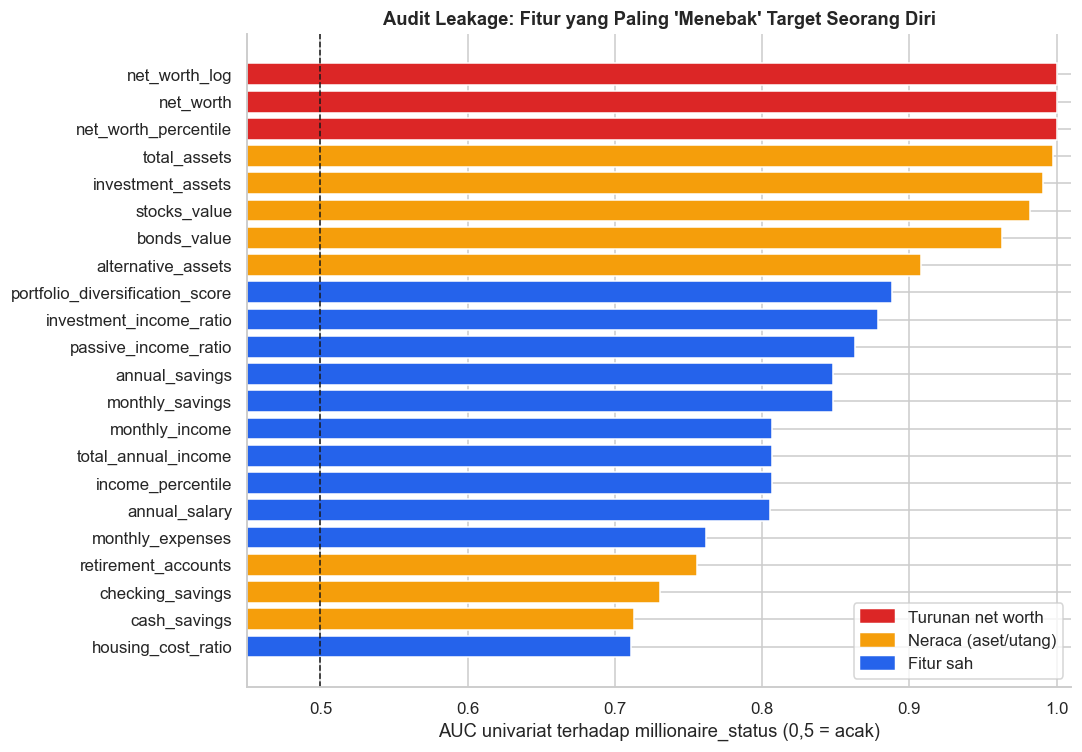

Dari 22 fitur 'paling prediktif', 11 adalah kolom turunan net worth / neraca.


In [6]:
# Kekuatan prediksi SATU fitur saja (AUC univariat): seberapa 'bocor' tiap kolom?
META = ["synthetic_person_id", "dataset_version", "generation_seed", "currency", "exchange_rate_to_usd"]
TARGET_DERIVED = ["net_worth", "net_worth_log", "net_worth_percentile", "wealth_bracket", "wealth_category",
                  "multi_millionaire_status", "financial_independence_status"]
BALANCE_SHEET = ["total_assets", "total_liabilities", "total_debt"] + BAL_ASSETS + BAL_LIAB

num_all = [c for c in df.select_dtypes("number").columns if c != TARGET]
uni_auc = {}
for c in num_all:
    x = df[c]
    if x.nunique(dropna=True) < 2: continue
    a = roc_auc_score(y_all, x.fillna(x.median()))
    uni_auc[c] = max(a, 1 - a)
uni_auc = pd.Series(uni_auc).sort_values(ascending=False)

def role(c):
    if c in TARGET_DERIVED: return "Turunan net worth"
    if c in BALANCE_SHEET:  return "Neraca (aset/utang)"
    if c in META:           return "Metadata"
    return "Fitur sah"

top = uni_auc.head(22)
colors = {"Turunan net worth": C["red"], "Neraca (aset/utang)": C["orange"], "Metadata": C["gray"], "Fitur sah": C["blue"]}
fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(top.index[::-1], top.values[::-1], color=[colors[role(c)] for c in top.index[::-1]])
ax.axvline(0.5, color="k", ls="--", lw=1)
ax.set_xlim(0.45, 1.01); ax.set_xlabel("AUC univariat terhadap millionaire_status (0,5 = acak)")
ax.set_title("Audit Leakage: Fitur yang Paling 'Menebak' Target Seorang Diri")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=v, label=k) for k, v in colors.items() if k != "Metadata"], loc="lower right")
savefig("03_audit_leakage"); plt.show()

n_leaky_top = sum(role(c) != "Fitur sah" for c in top.index)
print(f"Dari 22 fitur 'paling prediktif', {n_leaky_top} adalah kolom turunan net worth / neraca.")

### Empat set fitur

| Set | Nama | Yang dibuang | Fungsi |
|:--|:--|:--|:--|
| **A** | Leaky | Hanya metadata, `net_worth*`, `wealth_*`, `total_assets`, `total_liabilities` | Hanya untuk ablation: mengukur keuntungan palsu dari komponen neraca |
| **B** | Bersih (utama) | Semua dari A, ditambah seluruh komponen aset/utang dan `total_debt` | Set utama untuk semua eksperimen |
| **C** | Tanpa arus uang | Semua dari B, ditambah kolom arus uang (pendapatan, tabungan, investasi, pengeluaran, rasio turunannya) dan komposisi portofolio | Seberapa jauh perilaku, karier, dan demografi bisa memprediksi tanpa nominal uang |
| **D** | C tanpa indeks | Semua dari C, ditambah kolom berakhiran `_index` (mis. `wealth_building_index`) yang mungkin dibangun dari sinyal keuangan | Batas bawah paling ketat |

In [7]:
STRICT_EXTRA = [
    # pendapatan & arus kas
    "annual_salary", "annual_bonus", "other_income", "total_annual_income", "income_percentile", "monthly_income",
    "monthly_expenses", "monthly_savings", "annual_savings", "side_business_income", "passive_business_income",
    "business_revenue", "business_profit", "business_profit_margin",
    # investasi (jumlah uang) & komposisi portofolio
    "monthly_investment_amount", "annual_investment_amount", "stock_allocation", "bond_allocation",
    "real_estate_allocation", "cash_allocation", "alternative_asset_allocation", "portfolio_diversification_score",
    "asset_diversification_score", "retirement_investment_rate",
    # pengeluaran & utang (nominal)
    "annual_housing_cost", "annual_transport_cost", "annual_food_cost", "annual_entertainment_cost",
    "annual_travel_cost", "annual_health_cost", "annual_education_cost", "annual_luxury_spending",
    "annual_charity_donations", "mortgage_payment", "loan_payment", "credit_card_balance", "debt_to_income_ratio",
    # rasio & status turunan dari uang
    "savings_rate", "investment_rate", "passive_income_ratio", "investment_income_ratio", "business_income_ratio",
    "housing_cost_ratio", "luxury_spending_ratio", "emergency_fund_months", "financial_buffer_months",
    "high_saver_status", "high_investor_status", "entrepreneur_status", "high_debt_risk", "financial_stability_score",
]
STRICT_EXTRA = [c for c in STRICT_EXTRA if c in df.columns]

# Set A meniru persis daftar kolom yang dibuang di draf lama (14 kolom)
DROP_A = META + TARGET_DERIVED + ["total_assets", "total_liabilities"]
DROP_B = sorted(set(META + TARGET_DERIVED + BALANCE_SHEET))
DROP_C = sorted(set(DROP_B + STRICT_EXTRA))

ALL_FEATS = [c for c in df.columns if c != TARGET]
DROP_D = sorted(set(DROP_C + [c for c in ALL_FEATS if "_index" in c]))
FEATURE_SETS = {
    "A (leaky / draf lama)": [c for c in ALL_FEATS if c not in DROP_A],
    "B (bersih / utama)":    [c for c in ALL_FEATS if c not in DROP_B],
    "C (tanpa arus uang)":   [c for c in ALL_FEATS if c not in DROP_C],
    "D (C tanpa indeks komposit)": [c for c in ALL_FEATS if c not in DROP_D],
}
summary = pd.DataFrame({"Kolom dibuang": [len(DROP_A), len(DROP_B), len(DROP_C), len(DROP_D)],
                        "Fitur tersisa": [len(v) for v in FEATURE_SETS.values()]}, index=FEATURE_SETS.keys())
display(summary)
FEATURES_MAIN = FEATURE_SETS["B (bersih / utama)"]

,Kolom dibuang,Fitur tersisa
A (leaky / draf lama),14,259
B (bersih / utama),31,242
C (tanpa arus uang),82,191
D (C tanpa indeks komposit),85,188


---
## 6. Split dan Preprocessing

- **Split:** stratified 80% train, 10% validation, 10% test (sekali, `random_state=42`). Train untuk melatih bobot, validation untuk early stopping dan tuning, test hanya untuk laporan akhir (Bagian 12).
- **Preprocessing** hanya di-fit pada data latih (di CV di-fit ulang tiap fold): numerik dengan median imputation dan `StandardScaler`, kategorik dengan imputasi `'Missing'` dan `OneHotEncoder(handle_unknown='ignore')`.

In [8]:
idx_all = np.arange(len(df))
idx_tmp, idx_test = train_test_split(idx_all, test_size=0.10, random_state=SEED, stratify=y_all)
idx_train, idx_val = train_test_split(idx_tmp, test_size=1/9, random_state=SEED, stratify=y_all[idx_tmp])
Y = torch.tensor(y_all, dtype=torch.float32)

def make_preprocessor(num_cols, cat_cols):
    return ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), num_cols),
        ("cat", Pipeline([("imp", SimpleImputer(strategy="constant", fill_value="Missing")),
                          ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), cat_cols),
    ])

def clean_frame(feature_cols):
    X = df[feature_cols].copy()
    for c in X.select_dtypes("bool").columns: X[c] = X[c].astype(int)
    num = X.select_dtypes("number").columns.tolist()
    cat = [c for c in X.columns if c not in num]
    return X, num, cat

def build_matrices(feature_cols, idx_fit, idx_list):
    # Fit preprocessor pada idx_fit saja, transform ke semua idx di idx_list -> list tensor float32.
    X, num, cat = clean_frame(feature_cols)
    prep = make_preprocessor(num, cat).fit(X.iloc[idx_fit])
    mats = [torch.from_numpy(prep.transform(X.iloc[i]).astype(np.float32)) for i in idx_list]
    return prep, mats, num, cat

def feature_groups(prep, num, cat):
    # Peta: nama kolom asli -> daftar indeks kolom hasil transform (one-hot digabung per kolom asli).
    groups, pos = {}, 0
    for c in num: groups[c] = [pos]; pos += 1
    ohe = prep.named_transformers_["cat"].named_steps["ohe"]
    for c, cats in zip(cat, ohe.categories_):
        groups[c] = list(range(pos, pos + len(cats))); pos += len(cats)
    return groups

def prepare(feature_cols):
    prep, (Xtr, Xva, Xte), num, cat = build_matrices(feature_cols, idx_train, [idx_train, idx_val, idx_test])
    return SimpleNamespace(prep=prep, Xtr=Xtr, Xva=Xva, Xte=Xte, ytr=Y[idx_train], yva=Y[idx_val], yte=Y[idx_test],
                           num=num, cat=cat, groups=feature_groups(prep, num, cat), cols=feature_cols, dim=Xtr.shape[1])

t0 = time.time()
D = prepare(FEATURES_MAIN)      # data utama (Set B)
print(f"Train {len(idx_train):,} | Val {len(idx_val):,} | Test {len(idx_test):,}   (proporsi positif: "
      f"{Y[idx_train].mean():.3f} / {Y[idx_val].mean():.3f} / {Y[idx_test].mean():.3f})")
print(f"Set B: {len(FEATURES_MAIN)} kolom asli → {D.dim} fitur setelah one-hot  ({len(D.num)} numerik, {len(D.cat)} kategorikal)  [{time.time()-t0:.1f} dtk]")

Train 80,000 | Val 10,000 | Test 10,000   (proporsi positif: 0.425 / 0.425 / 0.425)
Set B: 242 kolom asli → 537 fitur setelah one-hot  (202 numerik, 40 kategorikal)  [10.6 dtk]


---
## 7. Arsitektur
Tiga MLP yang berbeda lebar dan kedalamannya, dilatih dengan resep yang sama supaya adil (materi kuliah: menambah node vs menambah layer).

| Model | Struktur | Ide |
|:--|:--|:--|
| **Baseline MLP** | $D \to 128 \to 64 \to 1$ (ReLU) | Pembanding sederhana tanpa regularisasi |
| **Deep Regularized MLP** | $D \to 256 \to 128 \to 64 \to 32 \to 1$ + BatchNorm + Dropout | Lebih dalam: empat hidden layer |
| **Wide Regularized MLP** | $D \to 512 \to 256 \to 1$ + BatchNorm + Dropout | Lebih lebar: dua hidden layer dengan 512 neuron |

Keluarannya logit (tanpa sigmoid) dan dilatih dengan `BCEWithLogitsLoss`.

In [9]:
class BaselineMLP(nn.Module):
    def __init__(self, d, h1=128, h2=64):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(d, h1), nn.ReLU(), nn.Linear(h1, h2), nn.ReLU(), nn.Linear(h2, 1))
    def forward(self, x): return self.net(x)

class DeepRegularizedMLP(nn.Module):
    def __init__(self, d, dropout=0.25):
        super().__init__()
        def blk(i, o, p): return [nn.Linear(i, o), nn.BatchNorm1d(o), nn.ReLU()] + ([nn.Dropout(p)] if p > 0 else [])
        self.net = nn.Sequential(*blk(d, 256, dropout), *blk(256, 128, dropout*0.8), *blk(128, 64, dropout*0.5),
                                 *blk(64, 32, 0.0), nn.Linear(32, 1))
    def forward(self, x): return self.net(x)

class WideRegularizedMLP(nn.Module):
    """
    Arsitektur Wide MLP: Memperbesar kapasitas representasi pada level abstraksi yang sama
    menggunakan hidden units yang lebih lebar (512 -> 256) dilengkapi BatchNorm dan Dropout.
    (Sesuai silabus PPT 2: efek penambahan node/lebar jaringan)
    """
    def __init__(self, d, h1=512, h2=256, dropout=0.25):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(d, h1), nn.BatchNorm1d(h1), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(h1, h2), nn.BatchNorm1d(h2), nn.ReLU(), nn.Dropout(dropout * 0.8),
            nn.Linear(h2, 1)
        )
    def forward(self, x): return self.net(x)

ARCHS = {"Baseline MLP": BaselineMLP, "Deep Regularized MLP": DeepRegularizedMLP, "Wide Regularized MLP": WideRegularizedMLP}
DEFAULT_KW = {"Baseline MLP": dict(h1=128, h2=64), "Deep Regularized MLP": dict(dropout=0.25),
              "Wide Regularized MLP": dict(h1=512, h2=256, dropout=0.25)}

def build_model(name, d, seed=SEED, **kw):
    seed_everything(seed)                                  # inisialisasi bobot reprodusibel
    return ARCHS[name](d, **{**DEFAULT_KW[name], **kw})

n_params = lambda m: sum(p.numel() for p in m.parameters() if p.requires_grad)
print(pd.DataFrame({n: {"Parameter": n_params(build_model(n, D.dim))} for n in ARCHS}).T.to_string())


                      Parameter
Baseline MLP              77185
Deep Regularized MLP     181953
Wide Regularized MLP     408577


---
## 8. Fungsi Pelatihan dan Evaluasi

Resep latih untuk semua model: AdamW (lr $10^{-3}$, weight decay $10^{-4}$), batch 512, `ReduceLROnPlateau` (faktor 0,5, sabar 2 epoch), early stopping pada `val_loss` (sabar 6 epoch), dan bobot terbaik dikembalikan secara eksplisit.

Kurva train dihitung dalam mode `eval()` pada subset tetap 20.000 data latih, supaya Dropout dan BatchNorm tidak mengotori perbandingan train vs validation.

In [10]:
@torch.no_grad()
def predict_logits(model, X, bs=8192):
    model.eval()
    return torch.cat([model(X[i:i+bs]) for i in range(0, len(X), bs)]).squeeze(1)

def metrics_from_logits(y, logits, thr=0.5):
    p = torch.sigmoid(logits).numpy(); yt = y.numpy(); pred = (p >= thr).astype(int)
    return dict(loss=float(F.binary_cross_entropy_with_logits(logits, y)),
                accuracy=accuracy_score(yt, pred), precision=precision_score(yt, pred, zero_division=0),
                recall=recall_score(yt, pred, zero_division=0), f1=f1_score(yt, pred, zero_division=0),
                roc_auc=roc_auc_score(yt, p), pr_auc=average_precision_score(yt, p), brier=brier_score_loss(yt, p))

def evaluate(model, X, y, thr=0.5):
    return metrics_from_logits(y, predict_logits(model, X), thr)

def make_optimizer(name, params, lr, wd):
    if name == "adamw":   return torch.optim.AdamW(params, lr=lr, weight_decay=wd)
    if name == "sgd":     return torch.optim.SGD(params, lr=lr, momentum=0.9, nesterov=True, weight_decay=wd)
    if name == "rmsprop": return torch.optim.RMSprop(params, lr=lr, weight_decay=wd)
    raise ValueError(name)

def fit(model, Xtr, ytr, Xva, yva, lr=LR, wd=WD, optimizer="adamw", max_epochs=MAX_EPOCHS,
        patience=PATIENCE, bs=BATCH_SIZE, seed=SEED, track_train=True):
    # Latih model; kembalikan (model dengan bobot terbaik, history, best_epoch, waktu).
    opt = make_optimizer(optimizer, model.parameters(), lr, wd)
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode="min", factor=0.5, patience=2)
    g = torch.Generator().manual_seed(seed)
    sub = torch.randperm(len(Xtr), generator=torch.Generator().manual_seed(0))[:20000]   # subset tetap utk kurva train
    hist = {k: [] for k in ["train_loss", "val_loss", "train_acc", "val_acc"]}
    best, best_state, best_ep, wait, t0 = float("inf"), None, 0, 0, time.time()
    for ep in range(1, max_epochs + 1):
        model.train()
        perm = torch.randperm(len(Xtr), generator=g)
        for i in range(0, len(perm), bs):
            b = perm[i:i+bs]
            if len(b) < 2: continue                               # BatchNorm butuh >1 sampel
            opt.zero_grad(); loss = F.binary_cross_entropy_with_logits(model(Xtr[b]).squeeze(1), ytr[b]); loss.backward(); opt.step()
        lv = predict_logits(model, Xva); vl = float(F.binary_cross_entropy_with_logits(lv, yva))
        hist["val_loss"].append(vl); hist["val_acc"].append(float(((lv > 0).float() == yva).float().mean()))
        if track_train:
            lt = predict_logits(model, Xtr[sub])
            hist["train_loss"].append(float(F.binary_cross_entropy_with_logits(lt, ytr[sub])))
            hist["train_acc"].append(float(((lt > 0).float() == ytr[sub]).float().mean()))
        sched.step(vl)
        if vl < best - 1e-5:
            best, best_ep, wait = vl, ep, 0
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
        else:
            wait += 1
            if wait >= patience: break
    model.load_state_dict(best_state)                              # kembalikan bobot terbaik
    return model, hist, best_ep, time.time() - t0

# Uji cepat fungsi (smoke test) pada 1 epoch
_m = build_model("Baseline MLP", D.dim)
_m, _h, _b, _t = fit(_m, D.Xtr, D.ytr, D.Xva, D.yva, max_epochs=1)
print(f"Smoke test OK — 1 epoch Baseline MLP: val_loss={_h['val_loss'][0]:.4f}, val_acc={_h['val_acc'][0]:.4f}  ({_t:.1f} dtk)")

Smoke test OK — 1 epoch Baseline MLP: val_loss=0.1532, val_acc=0.9349  (1.5 dtk)


---
## 9. Eksperimen 1: Benchmark 5-Fold CV

Ketiga arsitektur dilatih pada 5 fold stratified dari train+validation (90.000 data) dengan resep yang sama, preprocessing di-fit ulang tiap fold. Test set tidak disentuh.

**Pemilihan champion (aturan 1-SE):** ambil model dengan `val_loss` rata-rata terendah. Kalau ada model lain yang selisihnya masih dalam 1 standard error, pilih yang paling sederhana (parameter paling sedikit).

In [11]:
idx_tv = np.concatenate([idx_train, idx_val])
skf = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=SEED)
cv_rows = []
t_start = time.time()
for fold, (a, b) in enumerate(skf.split(idx_tv, y_all[idx_tv]), 1):
    prep_f, (Xa, Xb), _, _ = build_matrices(FEATURES_MAIN, idx_tv[a], [idx_tv[a], idx_tv[b]])
    ya, yb = Y[idx_tv[a]], Y[idx_tv[b]]
    for name in ARCHS:
        m = build_model(name, Xa.shape[1], seed=SEED + fold)
        m, h, be, dt = fit(m, Xa, ya, Xb, yb, seed=SEED + fold, track_train=False)
        r = evaluate(m, Xb, yb); r.update(model=name, fold=fold, best_epoch=be, seconds=dt, params=n_params(m))
        cv_rows.append(r)
    print(f"  fold {fold}/{CV_FOLDS} selesai  ({time.time()-t_start:.0f} dtk)")
cv = pd.DataFrame(cv_rows)
cv.to_csv(OUT_DIR / "cv_results_per_fold.csv", index=False)

agg = cv.groupby("model").agg(
    val_loss=("loss", "mean"), val_loss_sd=("loss", "std"), accuracy=("accuracy", "mean"), accuracy_sd=("accuracy", "std"),
    f1=("f1", "mean"), roc_auc=("roc_auc", "mean"), roc_auc_sd=("roc_auc", "std"),
    best_epoch=("best_epoch", "mean"), seconds=("seconds", "mean"), params=("params", "first")).loc[list(ARCHS)]
display(agg.style.format({"val_loss": "{:.4f}", "val_loss_sd": "{:.4f}", "accuracy": "{:.4f}", "accuracy_sd": "{:.4f}",
                          "f1": "{:.4f}", "roc_auc": "{:.4f}", "roc_auc_sd": "{:.4f}", "best_epoch": "{:.1f}",
                          "seconds": "{:.1f}", "params": "{:,.0f}"}).background_gradient(subset=["val_loss"], cmap="RdYlGn_r"))

# ---- Aturan champion (1-SE) ----
best_name = agg["val_loss"].idxmin()
se_best = agg.loc[best_name, "val_loss_sd"] / np.sqrt(CV_FOLDS)
within = agg[agg["val_loss"] <= agg.loc[best_name, "val_loss"] + se_best]
CHAMPION = within["params"].idxmin()
print(f"\nVal loss terendah : {best_name}   (SE = {se_best:.4f})")
print(f"Kandidat dalam 1 SE: {list(within.index)}")
print(f"🏆 CHAMPION        : {CHAMPION}")

  fold 1/5 selesai  (107 dtk)


  fold 2/5 selesai  (216 dtk)


  fold 3/5 selesai  (324 dtk)


  fold 4/5 selesai  (425 dtk)


  fold 5/5 selesai  (529 dtk)


,val_loss,val_loss_sd,accuracy,accuracy_sd,f1,roc_auc,roc_auc_sd,best_epoch,seconds,params
model,,,,,,,,,,
Baseline MLP,0.0894,0.0030,0.9629,0.0021,0.9562,0.9954,0.0005,5.8,13.4,"77,185"
Deep Regularized MLP,0.0932,0.0025,0.9609,0.0016,0.9538,0.9948,0.0003,5.2,36.2,"181,953"
Wide Regularized MLP,0.0976,0.0023,0.9584,0.0020,0.9509,0.9945,0.0003,5.2,48.5,"408,577"



Val loss terendah : Baseline MLP   (SE = 0.0014)
Kandidat dalam 1 SE: ['Baseline MLP']
🏆 CHAMPION        : Baseline MLP


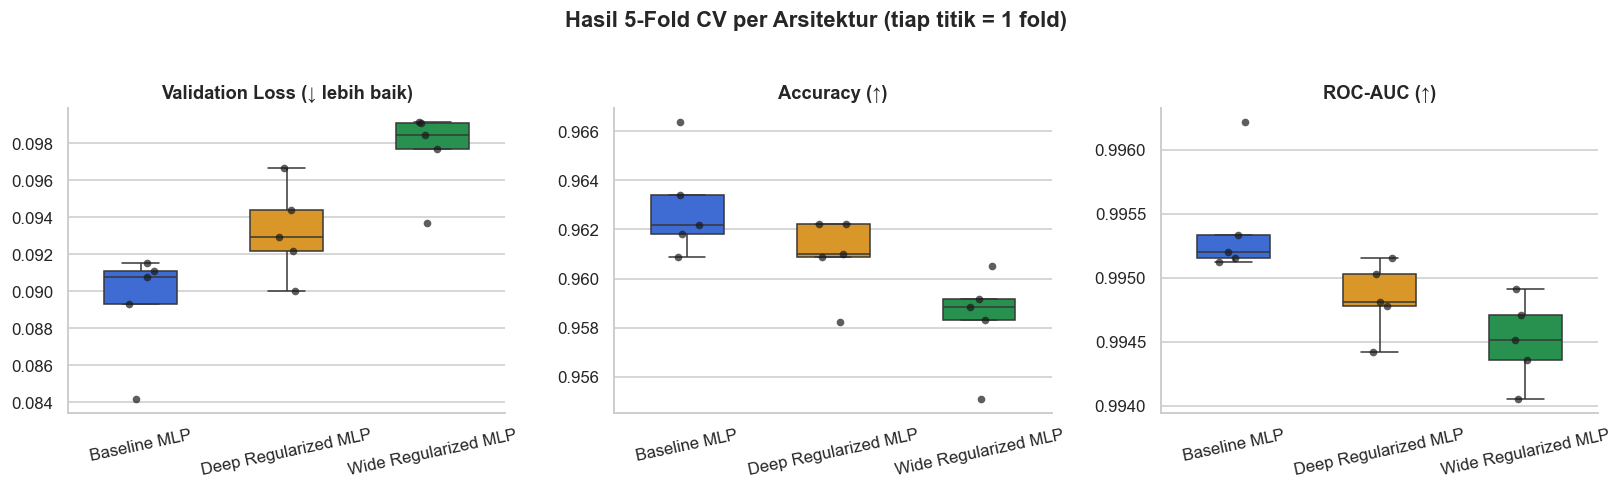

,Δ val_loss vs Baseline (rata-rata),Fold di mana lebih baik dari Baseline
Deep Regularized MLP,0.003865,0/5
Wide Regularized MLP,0.008232,0/5


In [12]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
for ax, (col, title) in zip(axes, [("loss", "Validation Loss (↓ lebih baik)"), ("accuracy", "Accuracy (↑)"), ("roc_auc", "ROC-AUC (↑)")]):
    sns.boxplot(data=cv, x="model", y=col, order=list(ARCHS), palette=MODEL_COLORS, ax=ax, width=.5, fliersize=0)
    sns.stripplot(data=cv, x="model", y=col, order=list(ARCHS), color="k", size=5, ax=ax, alpha=.7)
    ax.set_title(title); ax.set_xlabel(""); ax.set_ylabel(""); ax.tick_params(axis="x", rotation=12)
fig.suptitle(f"Hasil {CV_FOLDS}-Fold CV per Arsitektur (tiap titik = 1 fold)", fontweight="bold", y=1.03)
savefig("04_cv_benchmark"); plt.show()

# Perbandingan berpasangan terhadap Baseline (fold yang sama)
piv = cv.pivot(index="fold", columns="model", values="loss")
pair = pd.DataFrame({m: {"Δ val_loss vs Baseline (rata-rata)": (piv[m]-piv["Baseline MLP"]).mean(),
                         "Fold di mana lebih baik dari Baseline": f"{int((piv[m] < piv['Baseline MLP']).sum())}/{CV_FOLDS}"}
                     for m in ARCHS if m != "Baseline MLP"}).T
display(pair)

Boxplot menunjukkan variasi antar fold. Kalau kotak dua model saling tumpang tindih, selisih rata-ratanya belum tentu bermakna. Tabel berpasangan menunjukkan di berapa fold sebuah model benar-benar mengalahkan Baseline (Δ negatif berarti lebih baik).

---
## 10. Eksperimen 2: Tuning Champion

Tuning hanya untuk champion dan dinilai di validation set. Grid 3×3×3 = 27 kombinasi:

| Hyperparameter | Nilai |
|:--|:--|
| Learning rate | 1e-4, 3e-4, 1e-3 |
| Weight decay (AdamW) | 1e-4, 1e-2, 1e-1 (di AdamW peluruhan dikalikan learning rate, jadi nilai sekecil 1e-5 praktis tidak berefek) |
| Kapasitas | Baseline: lebar 32-16, 64-32, 128-64 · Deep: dropout 0,1/0,25/0,4 · Wide: 256-128/0,2, 512-256/0,25, 512-256/0,4 |

In [13]:
CAP_GRID = {
    "Baseline MLP":         [dict(h1=32, h2=16), dict(h1=64, h2=32), dict(h1=128, h2=64)],
    "Deep Regularized MLP": [dict(dropout=0.10), dict(dropout=0.25), dict(dropout=0.40)],
    "Wide Regularized MLP": [dict(h1=256, h2=128, dropout=0.20), dict(h1=512, h2=256, dropout=0.25), dict(h1=512, h2=256, dropout=0.40)],
}
cap_label = lambda kw: ", ".join(f"{k}={v}" for k, v in kw.items())

grid_rows, t0 = [], time.time()
for lr in [1e-4, 3e-4, 1e-3]:
    for wd in [1e-4, 1e-2, 1e-1]:
        for kw in CAP_GRID[CHAMPION]:
            m = build_model(CHAMPION, D.dim, **kw)
            m, h, be, dt = fit(m, D.Xtr, D.ytr, D.Xva, D.yva, lr=lr, wd=wd, track_train=False)
            r = evaluate(m, D.Xva, D.yva)
            grid_rows.append(dict(lr=lr, wd=wd, capacity=cap_label(kw), kw=kw, val_loss=r["loss"], val_acc=r["accuracy"],
                                  val_auc=r["roc_auc"], best_epoch=be))
grid = pd.DataFrame(grid_rows)
print(f"Grid selesai: {len(grid)} kombinasi dalam {time.time()-t0:.0f} dtk")

best_row = grid.loc[grid["val_loss"].idxmin()]
BEST_KW, BEST_LR, BEST_WD = best_row["kw"], float(best_row["lr"]), float(best_row["wd"])
display(grid.drop(columns="kw").sort_values("val_loss").head(8).style.format(
    {"lr": "{:.0e}", "wd": "{:.0e}", "val_loss": "{:.4f}", "val_acc": "{:.4f}", "val_auc": "{:.4f}"}))
print(f"✅ Konfigurasi terbaik (val_loss) → lr={BEST_LR:g}, wd={BEST_WD:g}, {cap_label(BEST_KW)}")
_cap_list = [cap_label(k) for k in CAP_GRID[CHAMPION]]
_edges = []
if BEST_LR in (1e-4, 1e-3): _edges.append("learning rate")
if BEST_WD in (1e-4, 1e-1): _edges.append("weight decay")
if cap_label(BEST_KW) in (_cap_list[0], _cap_list[-1]): _edges.append("kapasitas")
print("ℹ️ Optimum berada di TEPI grid untuk: " + ", ".join(_edges) + " → ruang pencarian bisa diperluas bila ada waktu." if _edges else "ℹ️ Optimum berada di bagian dalam grid (bukan di tepi) → rentang pencarian memadai.")


Grid selesai: 27 kombinasi dalam 384 dtk


,lr,wd,capacity,val_loss,val_acc,val_auc,best_epoch
10,3e-04,1e-04,"h1=64, h2=32",0.0726,0.9691,0.9967,15
13,3e-04,1e-02,"h1=64, h2=32",0.0727,0.9688,0.9967,15
16,3e-04,1e-01,"h1=64, h2=32",0.0727,0.9689,0.9967,15
5,1e-04,1e-02,"h1=128, h2=64",0.0729,0.9693,0.9967,30
2,1e-04,1e-04,"h1=128, h2=64",0.0730,0.9694,0.9967,30
8,1e-04,1e-01,"h1=128, h2=64",0.0739,0.9684,0.9966,28
15,3e-04,1e-01,"h1=32, h2=16",0.0741,0.9683,0.9966,28
12,3e-04,1e-02,"h1=32, h2=16",0.0746,0.9669,0.9966,28


✅ Konfigurasi terbaik (val_loss) → lr=0.0003, wd=0.0001, h1=64, h2=32
ℹ️ Optimum berada di TEPI grid untuk: weight decay → ruang pencarian bisa diperluas bila ada waktu.


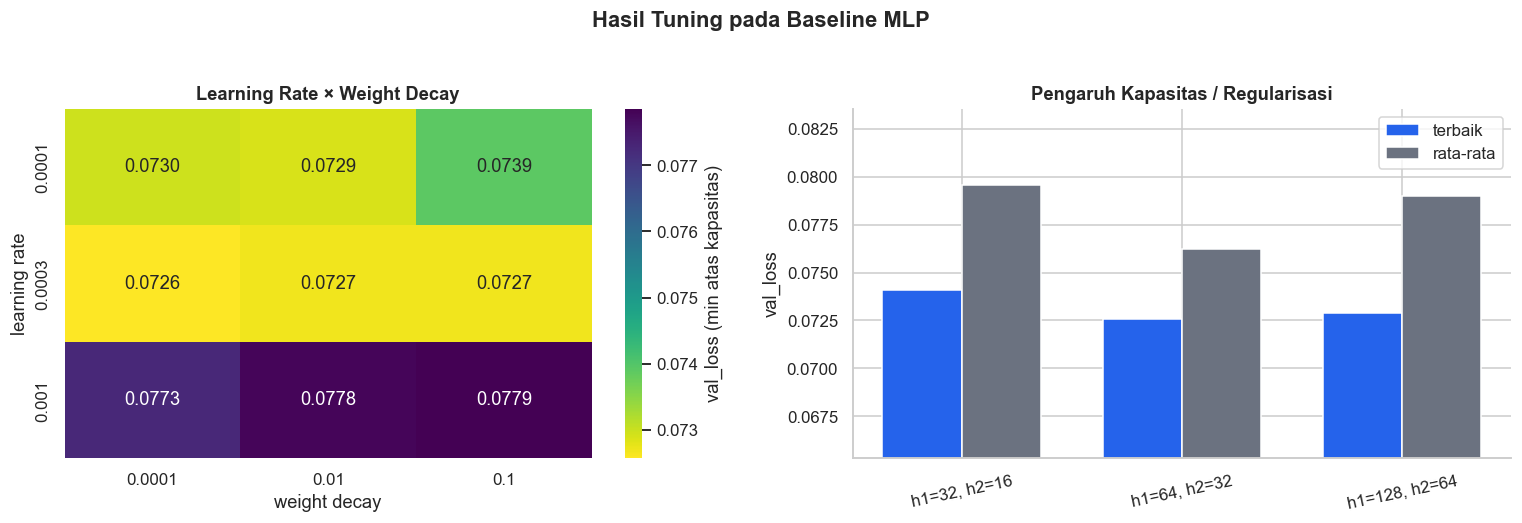

Rentang val_loss di seluruh grid: 0.0726 – 0.0884 (selisih 0.0159)


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
piv_lw = grid.pivot_table(index="lr", columns="wd", values="val_loss", aggfunc="min")
sns.heatmap(piv_lw, annot=True, fmt=".4f", cmap="viridis_r", ax=axes[0], cbar_kws={"label": "val_loss (min atas kapasitas)"})
axes[0].set_title("Learning Rate × Weight Decay"); axes[0].set_ylabel("learning rate"); axes[0].set_xlabel("weight decay")

cap_df = grid.groupby("capacity")["val_loss"].agg(["min", "mean"]).reindex([cap_label(k) for k in CAP_GRID[CHAMPION]])
x = np.arange(len(cap_df))
axes[1].bar(x-.18, cap_df["min"], .36, label="terbaik", color=C["blue"]); axes[1].bar(x+.18, cap_df["mean"], .36, label="rata-rata", color=C["gray"])
axes[1].set_xticks(x); axes[1].set_xticklabels(cap_df.index, rotation=12); axes[1].legend()
axes[1].set_title("Pengaruh Kapasitas / Regularisasi"); axes[1].set_ylabel("val_loss")
axes[1].set_ylim(cap_df["min"].min()*0.9, cap_df["mean"].max()*1.05)
fig.suptitle(f"Hasil Tuning pada {CHAMPION}", fontweight="bold", y=1.03)
savefig("05_tuning"); plt.show()
spread = grid["val_loss"].max() - grid["val_loss"].min()
print(f"Rentang val_loss di seluruh grid: {grid['val_loss'].min():.4f} – {grid['val_loss'].max():.4f} (selisih {spread:.4f})")

In [15]:
# Perbandingan optimizer pada konfigurasi terbaik (validation set)
opt_rows = []
for opt_name, lr_o in [("adamw", BEST_LR), ("sgd", 1e-2), ("rmsprop", 1e-3)]:
    m = build_model(CHAMPION, D.dim, **BEST_KW)
    m, h, be, dt = fit(m, D.Xtr, D.ytr, D.Xva, D.yva, lr=lr_o, wd=BEST_WD, optimizer=opt_name, track_train=False)
    r = evaluate(m, D.Xva, D.yva)
    opt_rows.append(dict(optimizer=opt_name, lr=lr_o, val_loss=r["loss"], val_acc=r["accuracy"], val_auc=r["roc_auc"], best_epoch=be, detik=dt))
opt_df = pd.DataFrame(opt_rows).set_index("optimizer")
display(opt_df.style.format({"lr": "{:.0e}", "val_loss": "{:.4f}", "val_acc": "{:.4f}", "val_auc": "{:.4f}", "detik": "{:.1f}"}))
BEST_OPT = opt_df["val_loss"].idxmin()
BEST_OPT_LR = float(opt_df.loc[BEST_OPT, "lr"])
print(f"✅ Optimizer terbaik di validation: {BEST_OPT} (lr={BEST_OPT_LR:g})")

,lr,val_loss,val_acc,val_auc,best_epoch,detik
optimizer,,,,,,
adamw,3e-04,0.0726,0.9691,0.9967,15,6.9
sgd,1e-02,0.0720,0.9694,0.9968,15,5.5
rmsprop,1e-03,0.0814,0.9667,0.9962,10,5.9


✅ Optimizer terbaik di validation: sgd (lr=0.01)


---
## 11. Eksperimen 3: Ablation

Champion dilatih ulang pada keempat set fitur (A, B, C, D) dengan konfigurasi yang sama untuk menjawab:
1. Berapa keuntungan palsu bila komponen neraca dibiarkan (A vs B)?
2. Seberapa jauh perilaku, karier, dan demografi memprediksi tanpa nominal uang (B vs C)?
3. Apakah indeks komposit seperti `wealth_building_index` menyumbang sinyal terselubung (C vs D)?

,fitur_asli,fitur_setelah_ohe,val_loss,test_acc,test_f1,test_auc,test_loss
set,,,,,,,
A (leaky / draf lama),259,554,0.0292,0.9886,0.9866,0.9995,0.0276
B (bersih / utama),242,537,0.0720,0.9681,0.9624,0.9970,0.0706
C (tanpa arus uang),191,486,0.4881,0.7631,0.7222,0.8406,0.4861
D (C tanpa indeks komposit),188,483,0.5191,0.7407,0.6960,0.8139,0.5193


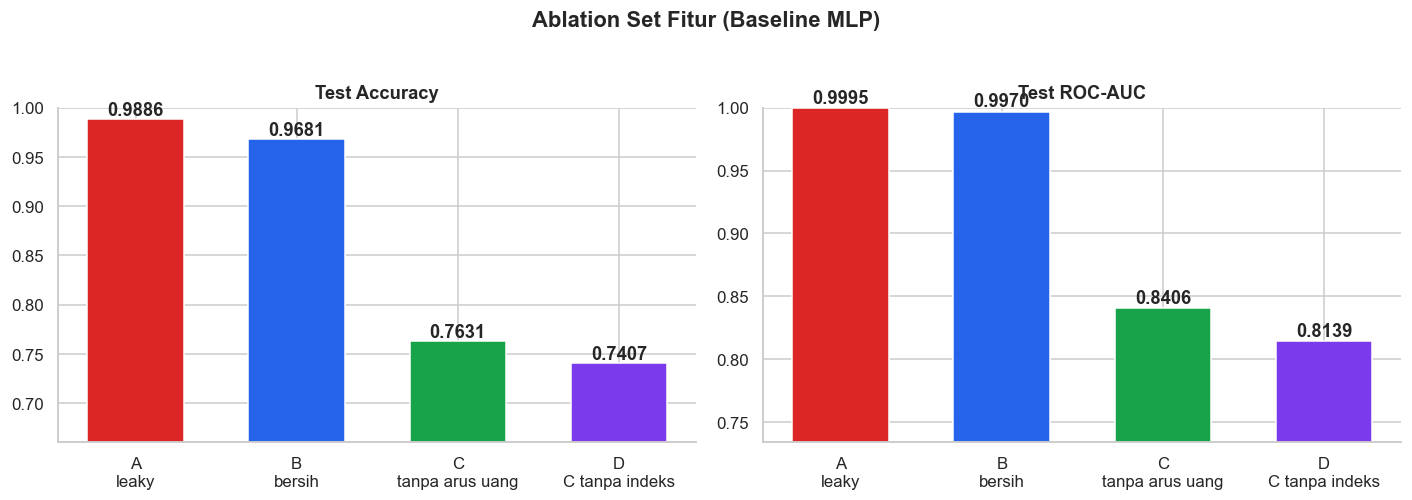

In [16]:
ablation, abl_models, abl_data = [], {}, {}
for label, cols in FEATURE_SETS.items():
    d = D if cols is FEATURES_MAIN else prepare(cols)
    m = build_model(CHAMPION, d.dim, **BEST_KW)
    m, h, be, dt = fit(m, d.Xtr, d.ytr, d.Xva, d.yva, lr=BEST_OPT_LR, wd=BEST_WD, optimizer=BEST_OPT, track_train=False)
    rv, rt = evaluate(m, d.Xva, d.yva), evaluate(m, d.Xte, d.yte)
    ablation.append(dict(set=label, fitur_asli=len(cols), fitur_setelah_ohe=d.dim, val_loss=rv["loss"],
                         test_acc=rt["accuracy"], test_f1=rt["f1"], test_auc=rt["roc_auc"], test_loss=rt["loss"]))
    abl_models[label], abl_data[label] = m, d
abl = pd.DataFrame(ablation).set_index("set")
display(abl.style.format({"val_loss": "{:.4f}", "test_acc": "{:.4f}", "test_f1": "{:.4f}", "test_auc": "{:.4f}", "test_loss": "{:.4f}"})
        .background_gradient(subset=["test_acc"], cmap="Blues"))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
cols_ab = [C["red"], C["blue"], C["green"], C["purple"]]
for ax, (col, title) in zip(axes, [("test_acc", "Test Accuracy"), ("test_auc", "Test ROC-AUC")]):
    ax.bar(["A\nleaky", "B\nbersih", "C\ntanpa arus uang", "D\nC tanpa indeks"], abl[col].values, color=cols_ab, width=.6)
    lo = abl[col].min(); ax.set_ylim(max(0.5, lo - 0.08), 1.0)
    for i, v in enumerate(abl[col].values): ax.text(i, v + 0.004, f"{v:.4f}", ha="center", fontweight="bold")
    ax.set_title(title)
fig.suptitle(f"Ablation Set Fitur ({CHAMPION})", fontweight="bold", y=1.03)
savefig("06_ablation_fitur"); plt.show()

---
## 12. Evaluasi Akhir di Test Set

Semua model dilatih di Set B dengan split yang sama, lalu dievaluasi sekali pada 10.000 data uji: tiga arsitektur dengan resep default, champion yang sudah dituning, dan dua pembanding klasik (Logistic Regression dan `HistGradientBoostingClassifier`).

In [17]:
final_models, final_hist, final_rows = {}, {}, []
for name in ARCHS:
    m = build_model(name, D.dim)
    m, h, be, dt = fit(m, D.Xtr, D.ytr, D.Xva, D.yva)
    final_models[name], final_hist[name] = m, dict(h, best_epoch=be)
    final_rows.append(dict(model=name, params=n_params(m), best_epoch=be, seconds=dt, **{f"test_{k}": v for k, v in evaluate(m, D.Xte, D.yte).items()}))

# Champion hasil tuning
CH_NAME = f"{CHAMPION} (tuned)"
m = build_model(CHAMPION, D.dim, **BEST_KW)
m, h, be, dt = fit(m, D.Xtr, D.ytr, D.Xva, D.yva, lr=BEST_OPT_LR, wd=BEST_WD, optimizer=BEST_OPT)
final_models[CH_NAME], final_hist[CH_NAME] = m, dict(h, best_epoch=be)
final_rows.append(dict(model=CH_NAME, params=n_params(m), best_epoch=be, seconds=dt, **{f"test_{k}": v for k, v in evaluate(m, D.Xte, D.yte).items()}))
CHAMP_MODEL = m

# Baseline klasik (scikit-learn)
Xtr_np, Xva_np, Xte_np = D.Xtr.numpy(), D.Xva.numpy(), D.Xte.numpy()
ytr_np, yte_np = D.ytr.numpy(), D.yte.numpy()
classic_proba = {}
for cname, clf in [("Logistic Regression", LogisticRegression(max_iter=2000, C=1.0)),
                   ("Gradient Boosting (HistGB)", HistGradientBoostingClassifier(max_iter=300, learning_rate=0.1, random_state=SEED))]:
    t0 = time.time(); clf.fit(Xtr_np, ytr_np); dt = time.time() - t0
    p = np.clip(clf.predict_proba(Xte_np)[:, 1], 1e-7, 1 - 1e-7); classic_proba[cname] = p
    logits = torch.tensor(np.log(p / (1 - p)), dtype=torch.float32)
    final_rows.append(dict(model=cname, params=np.nan, best_epoch=np.nan, seconds=dt, **{f"test_{k}": v for k, v in metrics_from_logits(D.yte, logits).items()}))

final = pd.DataFrame(final_rows).set_index("model")
show_cols = ["params", "seconds", "test_accuracy", "test_precision", "test_recall", "test_f1", "test_roc_auc", "test_pr_auc", "test_loss"]
display(final[show_cols].style.format({"params": "{:,.0f}", "seconds": "{:.1f}", **{c: "{:.4f}" for c in show_cols[2:]}})
        .background_gradient(subset=["test_accuracy", "test_roc_auc"], cmap="Greens"))
final.to_csv(OUT_DIR / "final_test_results.csv")

,params,seconds,test_accuracy,test_precision,test_recall,test_f1,test_roc_auc,test_pr_auc,test_loss
model,,,,,,,,,
Baseline MLP,"77,185",5.0,0.9656,0.9606,0.9583,0.9595,0.9960,0.9948,0.0814
Deep Regularized MLP,"181,953",24.0,0.9630,0.9679,0.9442,0.9559,0.9953,0.9939,0.0920
Wide Regularized MLP,"408,577",23.5,0.9572,0.9533,0.9456,0.9494,0.9944,0.9930,0.0957
Baseline MLP (tuned),"36,545",6.1,0.9681,0.9652,0.9595,0.9624,0.9970,0.9961,0.0706
Logistic Regression,nan,1.6,0.9522,0.9446,0.9428,0.9437,0.9906,0.9879,0.1238
Gradient Boosting (HistGB),nan,9.4,0.9721,0.9695,0.9647,0.9671,0.9974,0.9966,0.0663


### 12.1 Kurva Belajar
Garis putus-putus vertikal menandai epoch terbaik (bobot yang dikembalikan). Kalau val loss naik sementara train loss terus turun, itu tanda overfitting. Karena bobot terbaik di-restore, model akhir tidak ikut terdampak.

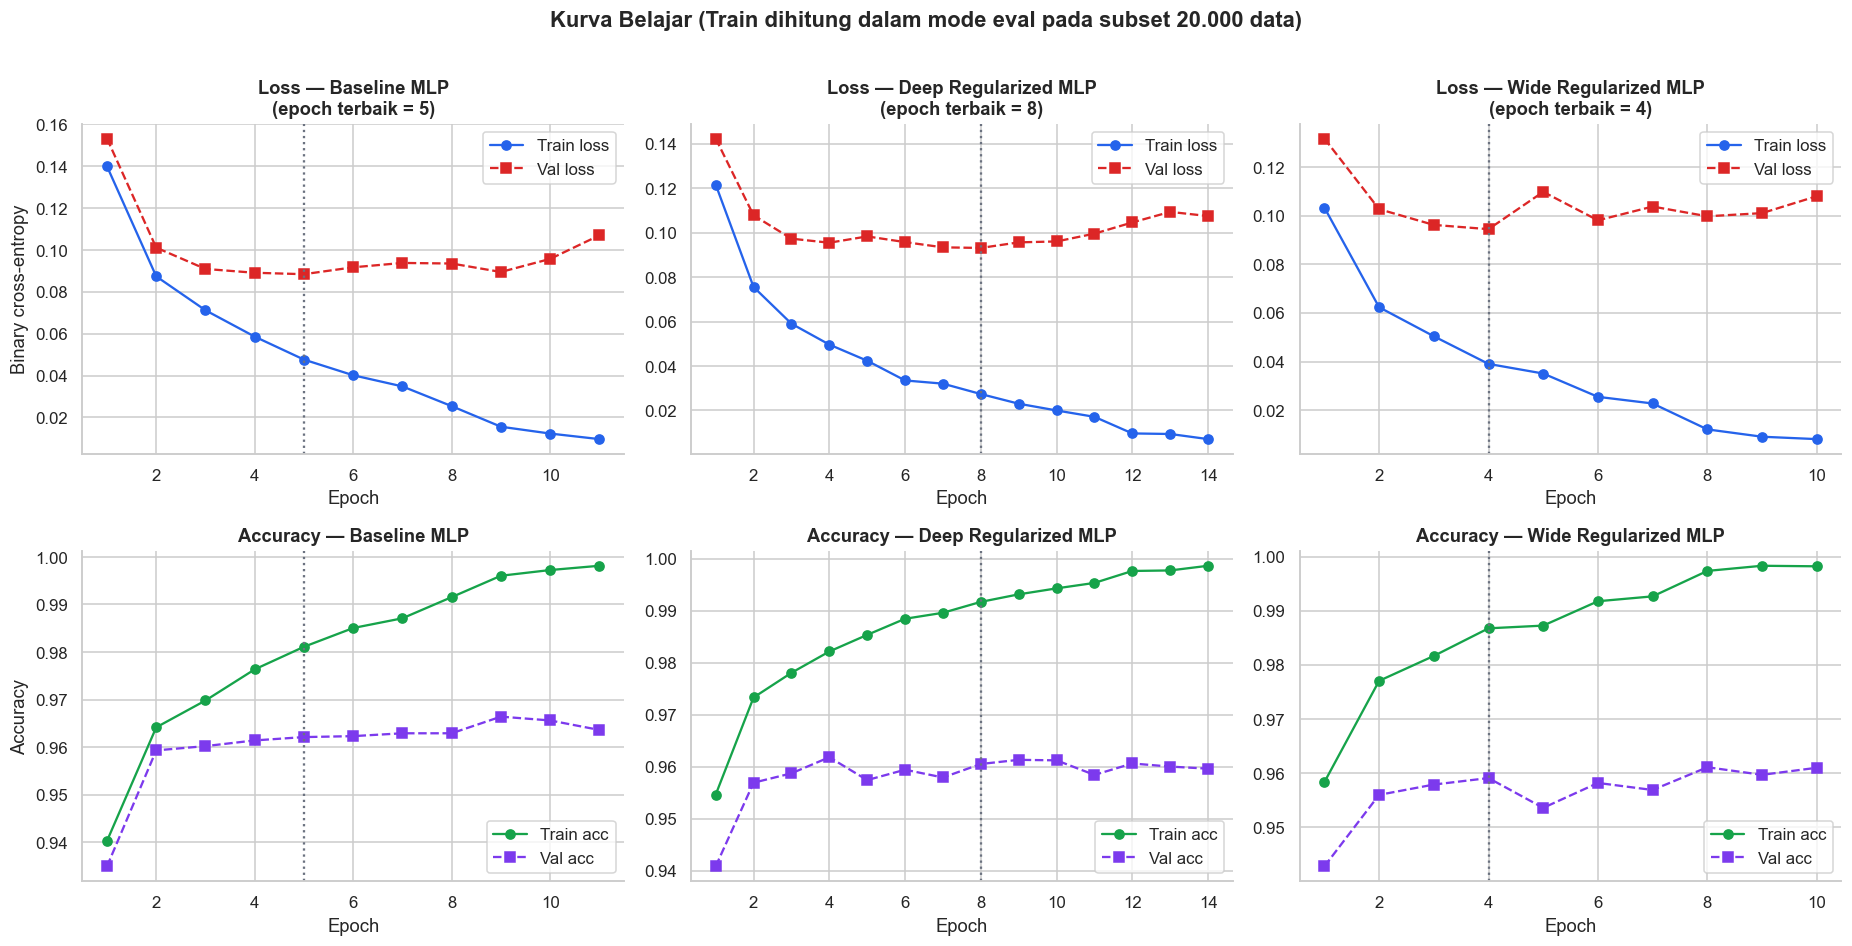

,Train loss @ terbaik,Val loss @ terbaik,Train acc @ terbaik,Val acc @ terbaik,Epoch dijalankan,Gap acc (train−val)
Baseline MLP,0.0476,0.0884,0.9811,0.9621,11,0.0190
Deep Regularized MLP,0.0274,0.0931,0.9917,0.9605,14,0.0312
Wide Regularized MLP,0.0390,0.0944,0.9868,0.9591,10,0.0276


In [18]:
fig, axes = plt.subplots(2, 3, figsize=(17, 8.5))
for j, name in enumerate(ARCHS):
    h = final_hist[name]; ep = np.arange(1, len(h["val_loss"]) + 1); be = h["best_epoch"]
    ax = axes[0, j]
    ax.plot(ep, h["train_loss"], "o-", color=C["blue"], label="Train loss"); ax.plot(ep, h["val_loss"], "s--", color=C["red"], label="Val loss")
    ax.axvline(be, color=C["gray"], ls=":", lw=1.5); ax.set_title(f"Loss — {name}\n(epoch terbaik = {be})"); ax.set_xlabel("Epoch"); ax.legend()
    if j == 0: ax.set_ylabel("Binary cross-entropy")
    ax = axes[1, j]
    ax.plot(ep, h["train_acc"], "o-", color=C["green"], label="Train acc"); ax.plot(ep, h["val_acc"], "s--", color=C["purple"], label="Val acc")
    ax.axvline(be, color=C["gray"], ls=":", lw=1.5); ax.set_title(f"Accuracy — {name}"); ax.set_xlabel("Epoch"); ax.legend(loc="lower right")
    if j == 0: ax.set_ylabel("Accuracy")
fig.suptitle("Kurva Belajar (Train dihitung dalam mode eval pada subset 20.000 data)", fontweight="bold", y=1.01)
savefig("07_kurva_belajar"); plt.show()

gap = pd.DataFrame({n: {"Train loss @ terbaik": final_hist[n]["train_loss"][final_hist[n]["best_epoch"]-1],
                        "Val loss @ terbaik":   final_hist[n]["val_loss"][final_hist[n]["best_epoch"]-1],
                        "Train acc @ terbaik":  final_hist[n]["train_acc"][final_hist[n]["best_epoch"]-1],
                        "Val acc @ terbaik":    final_hist[n]["val_acc"][final_hist[n]["best_epoch"]-1],
                        "Epoch dijalankan": len(final_hist[n]["val_loss"])} for n in ARCHS}).T
gap["Gap acc (train−val)"] = gap["Train acc @ terbaik"] - gap["Val acc @ terbaik"]
display(gap.style.format({c: "{:.4f}" for c in gap.columns if c != "Epoch dijalankan"} | {"Epoch dijalankan": "{:.0f}"}))

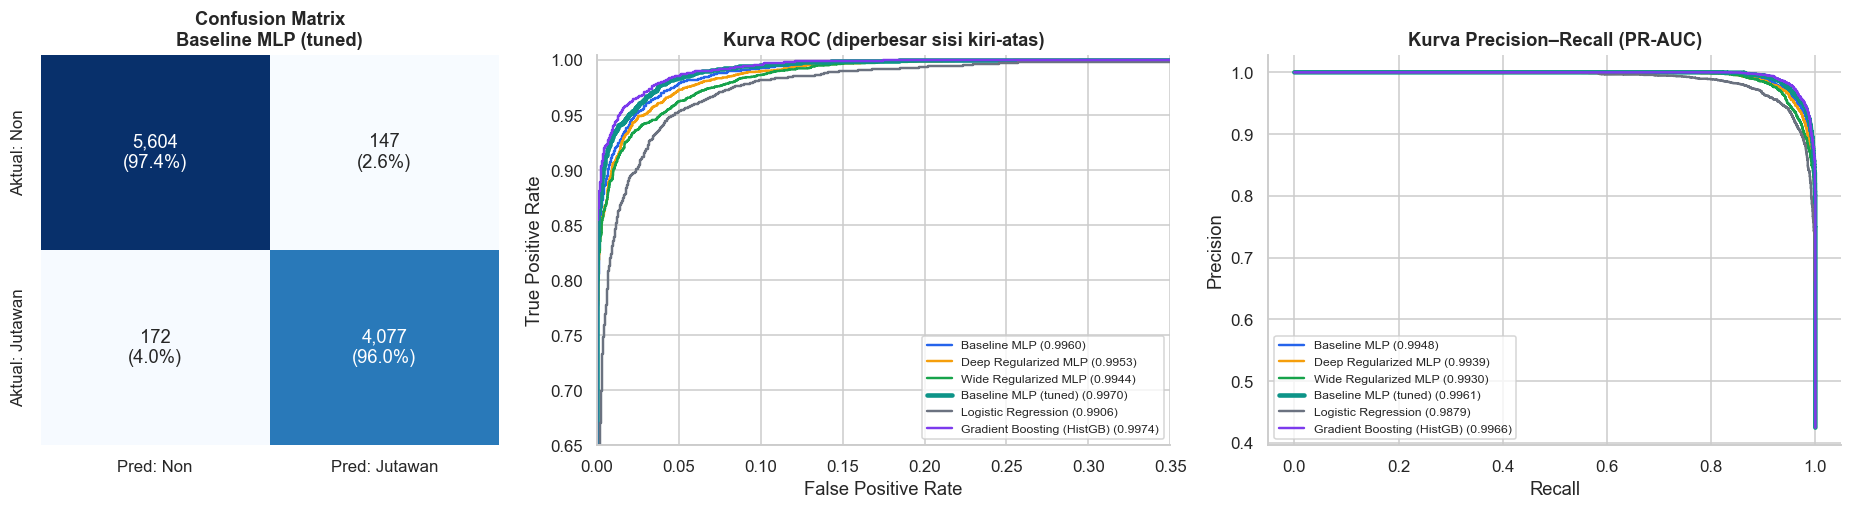

                 precision    recall  f1-score   support

Non-Millionaire     0.9702    0.9744    0.9723      5751
    Millionaire     0.9652    0.9595    0.9624      4249

       accuracy                         0.9681     10000
      macro avg     0.9677    0.9670    0.9673     10000
   weighted avg     0.9681    0.9681    0.9681     10000



In [19]:
# 12.2 Confusion matrix, ROC & PR (champion vs pembanding)
proba = {n: torch.sigmoid(predict_logits(final_models[n], D.Xte)).numpy() for n in final_models}
proba.update(classic_proba)

cm = confusion_matrix(yte_np, (proba[CH_NAME] >= 0.5).astype(int))
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8), gridspec_kw={"width_ratios": [1, 1.25, 1.25]})
annot = np.array([[f"{v:,}\n({v/cm[i].sum()*100:.1f}%)" for v in row] for i, row in enumerate(cm)])
sns.heatmap(cm, annot=annot, fmt="", cmap="Blues", cbar=False, ax=axes[0],
            xticklabels=["Pred: Non", "Pred: Jutawan"], yticklabels=["Aktual: Non", "Aktual: Jutawan"])
axes[0].set_title(f"Confusion Matrix\n{CH_NAME}")

palette = {**MODEL_COLORS, CH_NAME: C["teal"], "Logistic Regression": C["gray"], "Gradient Boosting (HistGB)": C["purple"]}
for n, p in proba.items():
    fpr, tpr, _ = roc_curve(yte_np, p); prc, rec, _ = precision_recall_curve(yte_np, p)
    lw = 3 if n == CH_NAME else 1.6
    axes[1].plot(fpr, tpr, color=palette[n], lw=lw, label=f"{n} ({roc_auc_score(yte_np, p):.4f})")
    axes[2].plot(rec, prc, color=palette[n], lw=lw, label=f"{n} ({average_precision_score(yte_np, p):.4f})")
axes[1].plot([0, 1], [0, 1], "k--", lw=1); axes[1].set_title("Kurva ROC (AUC)"); axes[1].set_xlabel("False Positive Rate"); axes[1].set_ylabel("True Positive Rate")
axes[1].legend(loc="lower right", fontsize=8)
axes[2].set_title("Kurva Precision–Recall (PR-AUC)"); axes[2].set_xlabel("Recall"); axes[2].set_ylabel("Precision"); axes[2].legend(loc="lower left", fontsize=8)
axes[1].set_xlim(0, .35); axes[1].set_ylim(.65, 1.005); axes[1].set_title("Kurva ROC (diperbesar sisi kiri-atas)")
savefig("08_cm_roc_pr"); plt.show()
print(classification_report(yte_np, (proba[CH_NAME] >= 0.5).astype(int), target_names=["Non-Millionaire", "Millionaire"], digits=4))

### 12.3 Kalibrasi dan Threshold
Akurasi tinggi belum tentu berarti probabilitasnya terkalibrasi. Kurva kalibrasi mengecek apakah prediksi 80% memang benar sekitar 80% kasus. Threshold alternatif dipilih di validation set (memaksimalkan F1), lalu diuji di test.

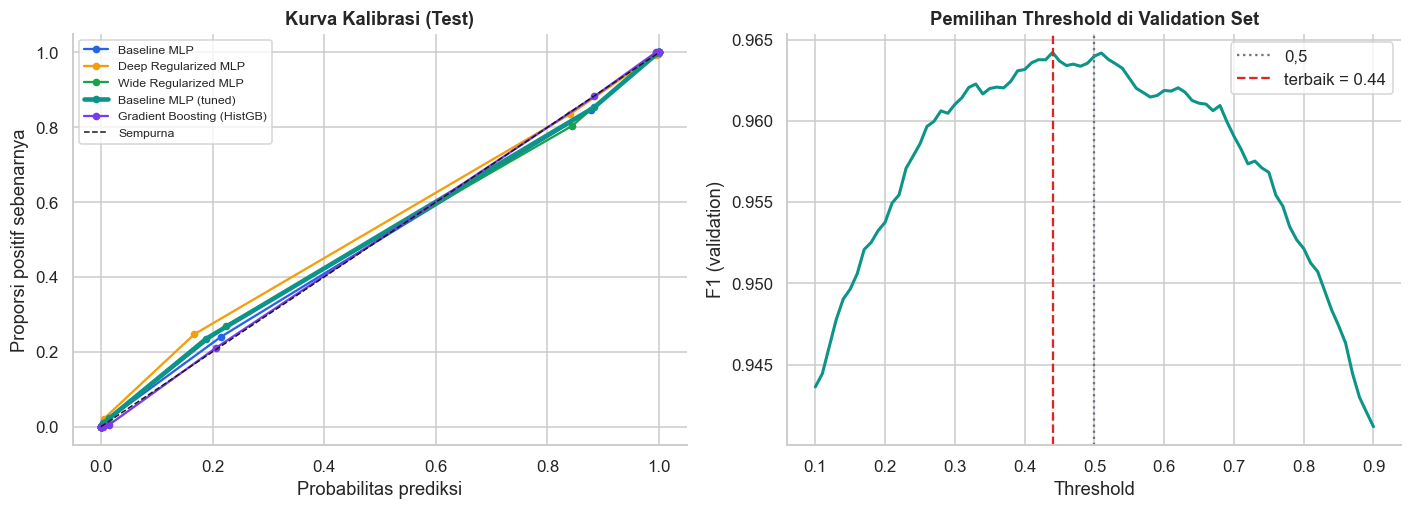

,"threshold 0,5",threshold 0.44 (dari validation)
accuracy,0.9681,0.9681
precision,0.9652,0.9604
recall,0.9595,0.9647
f1,0.9624,0.9625
brier,0.0220,0.0220


In [20]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for n in [ "Baseline MLP", "Deep Regularized MLP", "Wide Regularized MLP", CH_NAME, "Gradient Boosting (HistGB)"]:
    fo, mp = calibration_curve(yte_np, proba[n], n_bins=12, strategy="quantile")
    axes[0].plot(mp, fo, "o-", color=palette[n], lw=3 if n == CH_NAME else 1.5, label=n, ms=4)
axes[0].plot([0, 1], [0, 1], "k--", lw=1, label="Sempurna"); axes[0].set_xlabel("Probabilitas prediksi"); axes[0].set_ylabel("Proporsi positif sebenarnya")
axes[0].set_title("Kurva Kalibrasi (Test)"); axes[0].legend(fontsize=8)

pv = torch.sigmoid(predict_logits(CHAMP_MODEL, D.Xva)).numpy()
ths = np.linspace(0.1, 0.9, 81)
f1v = [f1_score(D.yva.numpy(), (pv >= t).astype(int)) for t in ths]
THR = float(ths[int(np.argmax(f1v))])
axes[1].plot(ths, f1v, color=C["teal"], lw=2); axes[1].axvline(0.5, color=C["gray"], ls=":", label="0,5"); axes[1].axvline(THR, color=C["red"], ls="--", label=f"terbaik = {THR:.2f}")
axes[1].set_xlabel("Threshold"); axes[1].set_ylabel("F1 (validation)"); axes[1].set_title("Pemilihan Threshold di Validation Set"); axes[1].legend()
savefig("09_kalibrasi_threshold"); plt.show()

r05 = metrics_from_logits(D.yte, predict_logits(CHAMP_MODEL, D.Xte), 0.5)
rth = metrics_from_logits(D.yte, predict_logits(CHAMP_MODEL, D.Xte), THR)
display(pd.DataFrame({"threshold 0,5": r05, f"threshold {THR:.2f} (dari validation)": rth}).loc[["accuracy", "precision", "recall", "f1", "brier"]].style.format("{:.4f}"))


### 12.4 Stabilitas antar Seed
Champion dilatih ulang dengan 5 seed berbeda (split tetap) untuk melihat sebaran hasilnya.

In [21]:
seed_rows = []
for s in range(N_SEEDS):
    m = build_model(CHAMPION, D.dim, seed=SEED + 100 + s, **BEST_KW)
    m, _, be, _ = fit(m, D.Xtr, D.ytr, D.Xva, D.yva, lr=BEST_OPT_LR, wd=BEST_WD, optimizer=BEST_OPT, seed=SEED + 100 + s, track_train=False)
    r = evaluate(m, D.Xte, D.yte); seed_rows.append(dict(seed=SEED + 100 + s, test_acc=r["accuracy"], test_f1=r["f1"], test_auc=r["roc_auc"], best_epoch=be))
seeds_df = pd.DataFrame(seed_rows).set_index("seed")
display(seeds_df.style.format({"test_acc": "{:.4f}", "test_f1": "{:.4f}", "test_auc": "{:.4f}"}))
SEED_STATS = seeds_df.agg(["mean", "std"])
print(f"Accuracy = {SEED_STATS.loc['mean','test_acc']*100:.2f}% ± {SEED_STATS.loc['std','test_acc']*100:.2f}%   |   ROC-AUC = {SEED_STATS.loc['mean','test_auc']:.4f} ± {SEED_STATS.loc['std','test_auc']:.4f}")

,test_acc,test_f1,test_auc,best_epoch
seed,,,,
142,0.9688,0.9633,0.9967,12
143,0.9689,0.9633,0.9970,18
144,0.9695,0.9640,0.9968,19
145,0.9679,0.9622,0.9969,16
146,0.9692,0.9637,0.9970,21


Accuracy = 96.89% ± 0.06%   |   ROC-AUC = 0.9969 ± 0.0001


---
## 13. Permutation Importance

Tiap kolom asli (hasil one-hot digabung lagi) diacak di test set, lalu diukur penurunan ROC-AUC. Makin besar penurunannya, makin bergantung model pada kolom itu. Diulang 3× per kolom (batang galat = std).

Dihitung untuk Set B, Set C, dan Set D. Set C dan D paling relevan untuk pertanyaan "kebiasaan apa yang membedakan jutawan", karena tidak memuat nominal uang.

In [22]:
@torch.no_grad()
def permutation_importance(model, d, n_repeats=3, seed=SEED):
    g = torch.Generator().manual_seed(seed)
    base = roc_auc_score(d.yte.numpy(), predict_logits(model, d.Xte).numpy())
    rows = []
    for col, idx in d.groups.items():
        drops = []
        for _ in range(n_repeats):
            Xp = d.Xte.clone(); perm = torch.randperm(len(Xp), generator=g)
            Xp[:, idx] = d.Xte[perm][:, idx]
            drops.append(base - roc_auc_score(d.yte.numpy(), predict_logits(model, Xp).numpy()))
        rows.append((col, np.mean(drops), np.std(drops)))
    return base, pd.DataFrame(rows, columns=["feature", "auc_drop", "std"]).sort_values("auc_drop", ascending=False).reset_index(drop=True)

t0 = time.time()
base_B, imp_B = permutation_importance(CHAMP_MODEL, D)
base_C, imp_C = permutation_importance(abl_models["C (tanpa arus uang)"], abl_data["C (tanpa arus uang)"])
base_D, imp_D = permutation_importance(abl_models["D (C tanpa indeks komposit)"], abl_data["D (C tanpa indeks komposit)"])
print(f"Permutation importance selesai: {len(imp_B)} / {len(imp_C)} / {len(imp_D)} kolom (Set B / C / D) dalam {time.time()-t0:.0f} dtk")
print(f"ROC-AUC dasar  Set B = {base_B:.4f} | Set C = {base_C:.4f} | Set D = {base_D:.4f}")
for nm, imp in [("B", imp_B), ("C", imp_C), ("D", imp_D)]: imp.to_csv(OUT_DIR / f"permutation_importance_set{nm}.csv", index=False)

Permutation importance selesai: 242 / 191 / 188 kolom (Set B / C / D) dalam 24 dtk
ROC-AUC dasar  Set B = 0.9970 | Set C = 0.8406 | Set D = 0.8139


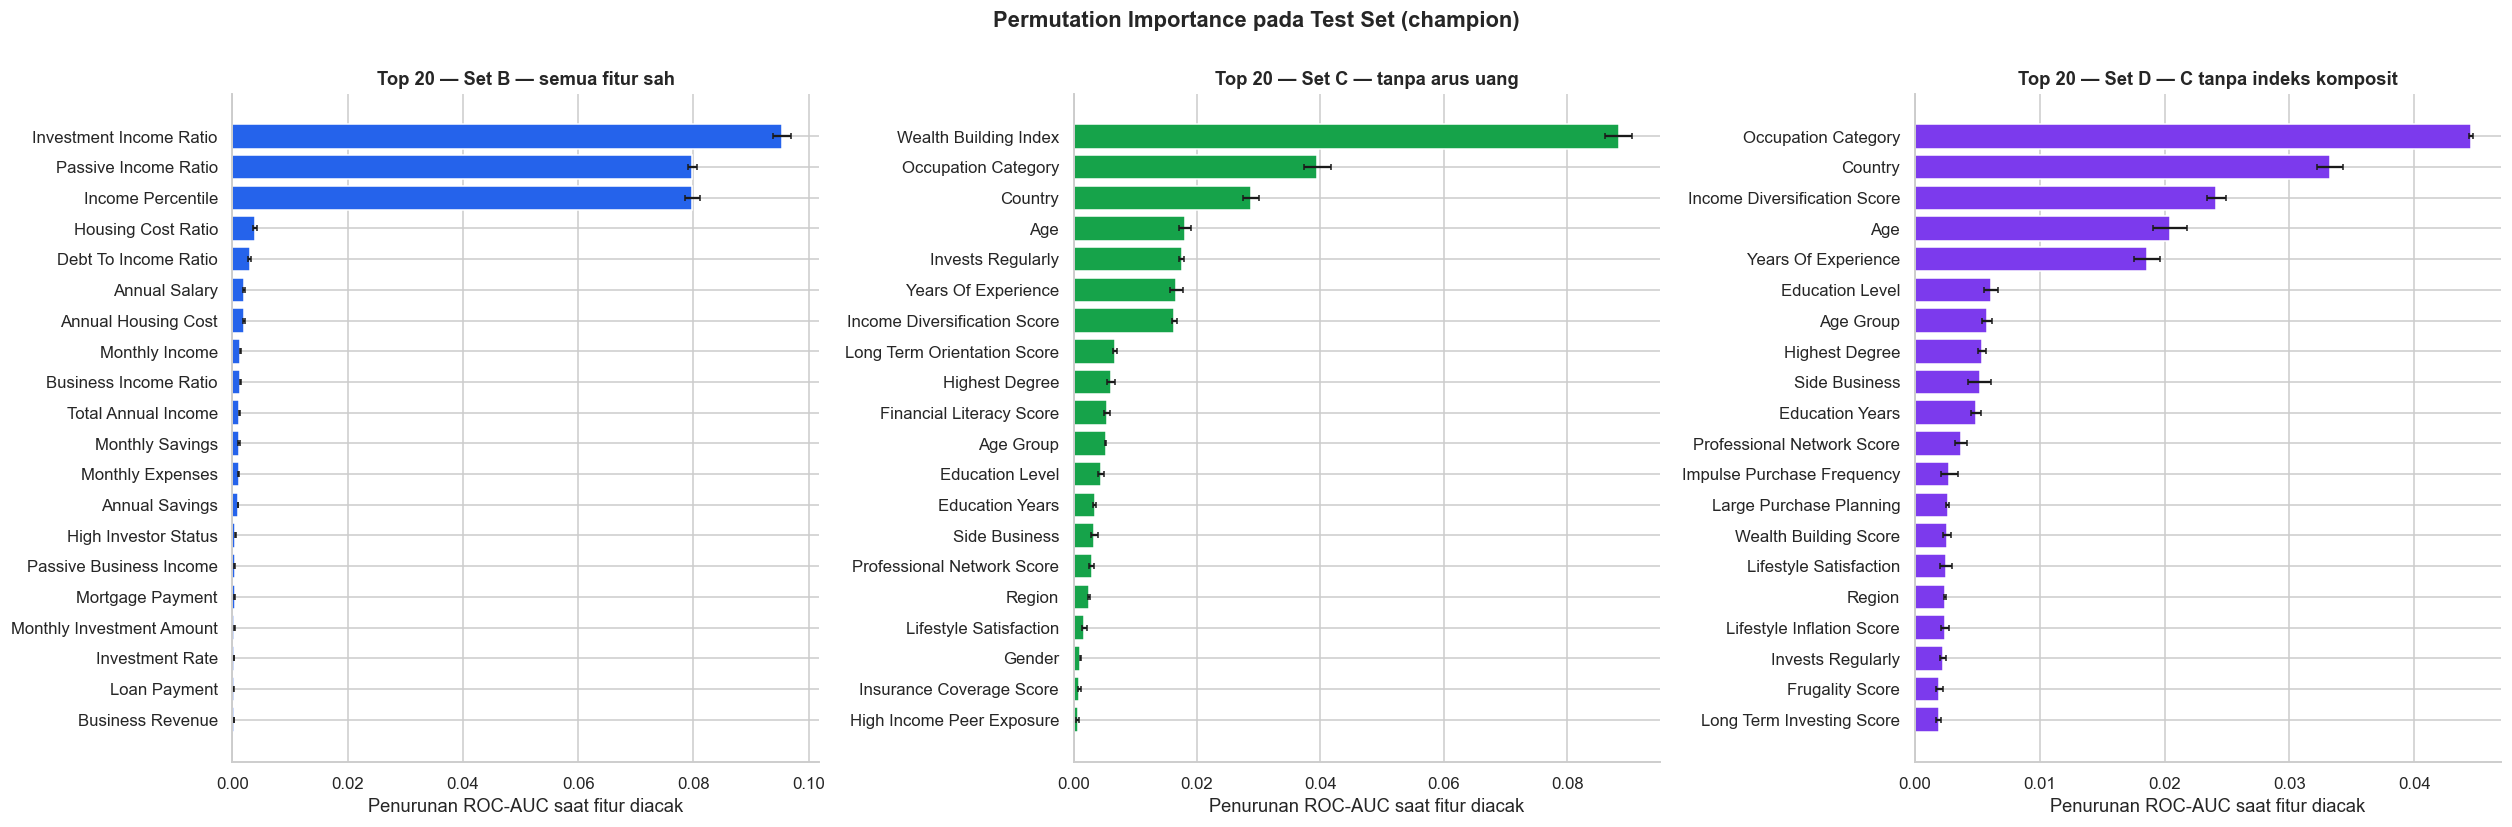

Top 5 Set B: investment_income_ratio, passive_income_ratio, income_percentile, housing_cost_ratio, debt_to_income_ratio
Top 5 Set C: wealth_building_index, occupation_category, country, age, invests_regularly
Top 5 Set D: occupation_category, country, income_diversification_score, age, years_of_experience


In [23]:
nice = lambda c: c.replace("_", " ").title()
fig, axes = plt.subplots(1, 3, figsize=(23, 7.5))
for ax, imp, ttl, col in [(axes[0], imp_B, "Set B — semua fitur sah", C["blue"]), (axes[1], imp_C, "Set C — tanpa arus uang", C["green"]), (axes[2], imp_D, "Set D — C tanpa indeks komposit", C["purple"])]:
    t = imp.head(20)[::-1]
    ax.barh([nice(c) for c in t.feature], t.auc_drop, xerr=t["std"], color=col, ecolor="k", capsize=2)
    ax.set_title(f"Top 20 — {ttl}"); ax.set_xlabel("Penurunan ROC-AUC saat fitur diacak")
fig.suptitle("Permutation Importance pada Test Set (champion)", fontweight="bold", y=1.0)
savefig("10_permutation_importance"); plt.show()
print("Top 5 Set B:", ", ".join(imp_B.feature.head(5)))
print("Top 5 Set C:", ", ".join(imp_C.feature.head(5)))
print("Top 5 Set D:", ", ".join(imp_D.feature.head(5)))

> **Catatan.** Permutation importance mengukur ketergantungan model, bukan sebab-akibat. Fitur yang berkorelasi (mis. `monthly_income`, `annual_salary`, `total_annual_income`) saling berbagi nilai penting, sehingga masing-masing tampak lebih kecil. Datanya juga sintetis, jadi polanya mencerminkan aturan pembangkit data, belum tentu dunia nyata.

---
## 14. Fungsi Inferensi
Menerima profil satu individu (dictionary; kolom yang tidak diisi diimputasi seperti saat pelatihan) dan mengembalikan probabilitas serta kelasnya.

In [24]:
def predict_millionaire(profile: dict, model=None, data=D, threshold=0.5):
    # Prediksi probabilitas jutawan dari satu profil. Kolom yang tidak diberikan -> NaN -> diimputasi pipeline.
    model = model or CHAMP_MODEL
    row = pd.DataFrame([{c: profile.get(c, np.nan) for c in data.cols}])
    for c in data.num: row[c] = pd.to_numeric(row[c], errors="coerce")
    x = torch.from_numpy(data.prep.transform(row).astype(np.float32))
    p = float(torch.sigmoid(predict_logits(model, x))[0])
    return {"probabilitas_jutawan": round(p, 4), "prediksi": "🌟 Jutawan" if p >= threshold else "🌱 Bukan jutawan", "threshold": threshold}

X_te_raw = df.iloc[idx_test]
for k in range(3):
    prof = X_te_raw.iloc[k][FEATURES_MAIN].to_dict()
    print(f"Sampel {k+1} (label asli = {int(X_te_raw.iloc[k][TARGET])}):", predict_millionaire(prof, threshold=THR))
print("Profil sebagian (hanya 3 kolom):", predict_millionaire({"savings_rate": 0.35, "financial_literacy_score": 80, "age": 45}, threshold=THR))

Sampel 1 (label asli = 0): {'probabilitas_jutawan': 0.0, 'prediksi': '🌱 Bukan jutawan', 'threshold': 0.44000000000000006}
Sampel 2 (label asli = 0): {'probabilitas_jutawan': 0.0919, 'prediksi': '🌱 Bukan jutawan', 'threshold': 0.44000000000000006}
Sampel 3 (label asli = 1): {'probabilitas_jutawan': 1.0, 'prediksi': '🌟 Jutawan', 'threshold': 0.44000000000000006}
Profil sebagian (hanya 3 kolom): {'probabilitas_jutawan': 0.0018, 'prediksi': '🌱 Bukan jutawan', 'threshold': 0.44000000000000006}


---
## 14b. Tambahan di Luar Silabus: Tabular ResNet

Bagian 9-12 membandingkan tiga arsitektur sesuai silabus dan champion sudah dipilih sebelum bagian ini. Tabular ResNet (skip connection, Gorishniy dkk., 2021) bukan materi silabus, jadi tidak ikut pemilihan champion dan tidak mengubah angka utama. Pertanyaannya cuma satu: apakah arsitektur residual memberi keuntungan nyata dibanding champion?

Supaya adil, fold CV, resep latih, dan anggaran tuning (grid 27 kombinasi + perbandingan optimizer, hanya di validation) dibuat sama dengan champion. Test set dipakai sekali untuk ResNet default dan ResNet tuned.

In [ ]:
class ResBlock(nn.Module):
    # Blok residual pre-norm: x + F(x), F = BN -> Linear -> GELU -> Dropout -> Linear -> Dropout
    def __init__(self, w, dropout):
        super().__init__()
        self.f = nn.Sequential(nn.BatchNorm1d(w), nn.Linear(w, w), nn.GELU(), nn.Dropout(dropout),
                               nn.Linear(w, w), nn.Dropout(dropout))
    def forward(self, x): return x + self.f(x)

class TabularResNet(nn.Module):
    def __init__(self, d, width=128, n_blocks=3, dropout=0.2):
        super().__init__()
        self.inp = nn.Linear(d, width)
        self.blocks = nn.Sequential(*[ResBlock(width, dropout) for _ in range(n_blocks)])
        self.head = nn.Sequential(nn.BatchNorm1d(width), nn.GELU(), nn.Linear(width, 1))
    def forward(self, x): return self.head(self.blocks(self.inp(x)))

def build_resnet(d, seed=SEED, **kw):
    seed_everything(seed)
    return TabularResNet(d, **{**dict(width=128, n_blocks=3, dropout=0.2), **kw})

try: CHAMPION
except NameError: CHAMPION = "Baseline MLP"   # cadangan bila Bagian 9 belum dijalankan
# Sengaja TIDAK dimasukkan ke ARCHS: ResNet tidak ikut pemilihan champion.
print(f"Tabular ResNet (default: lebar 128, 3 blok): {n_params(build_resnet(D.dim)):,} parameter")

# Angka pembanding dari Bagian 12 (dibaca langsung bila variabelnya ada; cadangan = nilai yang tercatat di notebook)
try:
    _f = final; _ss = SEED_STATS
    REF = {k: {m: float(_f.loc[n, f"test_{m}"]) for m in ["accuracy", "f1", "roc_auc", "loss"]}
           for k, n in [("Baseline MLP", "Baseline MLP"), ("Baseline MLP (tuned)", "Baseline MLP (tuned)"),
                        ("Gradient Boosting", "Gradient Boosting (HistGB)")]}
    REF_SEED = (float(_ss.loc["mean", "test_acc"]), float(_ss.loc["std", "test_acc"]))
    print("Pembanding: dibaca dari variabel Bagian 12 & 12.4")
except NameError:
    REF = {"Baseline MLP":          dict(accuracy=.9656, f1=.9595, roc_auc=.9960, loss=.0814),
           "Baseline MLP (tuned)":  dict(accuracy=.9681, f1=.9624, roc_auc=.9970, loss=.0706),
           "Gradient Boosting":     dict(accuracy=.9721, f1=.9671, roc_auc=.9974, loss=.0663)}
    REF_SEED = (.9689, .0006)
    print("Pembanding: nilai tercatat dari Bagian 12 & 12.4 (variabel tidak tersedia di sesi ini)")

Tabular ResNet (default: lebar 128, 3 blok): 169,089 parameter
Pembanding: nilai tercatat dari Bagian 12 & 12.4 (variabel tidak tersedia di sesi ini)


In [ ]:
# --- 14b.1  5-fold CV: Baseline MLP vs Tabular ResNet, fold PERSIS sama dengan Bagian 9 ---
idx_tv = np.concatenate([idx_train, idx_val])
skf_x = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=SEED)
xrows, t_start = [], time.time()
for fold, (a, b) in enumerate(skf_x.split(idx_tv, y_all[idx_tv]), 1):
    _, (Xa, Xb), _, _ = build_matrices(FEATURES_MAIN, idx_tv[a], [idx_tv[a], idx_tv[b]])
    ya, yb = Y[idx_tv[a]], Y[idx_tv[b]]
    for name, mk in [("Baseline MLP", lambda d, s: build_model("Baseline MLP", d, seed=s)),
                     ("Tabular ResNet", lambda d, s: build_resnet(d, seed=s))]:
        m = mk(Xa.shape[1], SEED + fold)
        m, h, be, dt = fit(m, Xa, ya, Xb, yb, seed=SEED + fold, track_train=False)
        r = evaluate(m, Xb, yb); r.update(model=name, fold=fold, best_epoch=be, seconds=dt, params=n_params(m)); xrows.append(r)
    print(f"  fold {fold}/{CV_FOLDS} selesai  ({time.time()-t_start:.0f} dtk)")
xcv = pd.DataFrame(xrows)
xagg = xcv.groupby("model").agg(val_loss=("loss", "mean"), val_loss_sd=("loss", "std"), accuracy=("accuracy", "mean"),
                                accuracy_sd=("accuracy", "std"), roc_auc=("roc_auc", "mean"), params=("params", "first"))
display(xagg.style.format({"val_loss": "{:.4f}", "val_loss_sd": "{:.4f}", "accuracy": "{:.4f}", "accuracy_sd": "{:.4f}",
                           "roc_auc": "{:.4f}", "params": "{:,.0f}"}))
xpiv = xcv.pivot(index="fold", columns="model", values="loss")
X_WINS = int((xpiv["Tabular ResNet"] < xpiv["Baseline MLP"]).sum())
X_DLOSS = float((xpiv["Tabular ResNet"] - xpiv["Baseline MLP"]).mean())
print(f"ResNet vs Baseline: Δ val-loss rata-rata = {X_DLOSS:+.4f} (negatif = ResNet lebih baik); lebih baik di {X_WINS}/{CV_FOLDS} fold")
print("Catatan: Baseline dihitung ulang di sini pada fold yang sama untuk perbandingan berpasangan; selisih sangat kecil dari tabel Bagian 9 itu wajar.")

  fold 1/5 selesai  (55 dtk)


  fold 2/5 selesai  (111 dtk)


  fold 3/5 selesai  (162 dtk)


  fold 4/5 selesai  (214 dtk)


  fold 5/5 selesai  (262 dtk)


,val_loss,val_loss_sd,accuracy,accuracy_sd,roc_auc,params
model,,,,,,
Baseline MLP,0.0891,0.0028,0.9626,0.0021,0.9954,"77,185"
Tabular ResNet,0.0844,0.0030,0.9639,0.0018,0.9957,"169,089"


ResNet vs Baseline: Δ val-loss rata-rata = -0.0047 (negatif = ResNet lebih baik); lebih baik di 5/5 fold
Catatan: Baseline dihitung ulang di sini pada fold yang sama untuk perbandingan berpasangan; selisih sangat kecil dari tabel Bagian 9 itu wajar.


In [ ]:
# --- 14b.2  Tuning ResNet dengan protokol yang sama seperti champion (hanya di validation) ---
RES_GRID_W = [32, 64, 128]
xg_rows, t0 = [], time.time()
for lr in [1e-4, 3e-4, 1e-3]:
    for wd in [1e-4, 1e-2, 1e-1]:
        for w in RES_GRID_W:
            m = build_resnet(D.dim, width=w)
            m, h, be, dt = fit(m, D.Xtr, D.ytr, D.Xva, D.yva, lr=lr, wd=wd, track_train=False)
            r = evaluate(m, D.Xva, D.yva)
            xg_rows.append(dict(lr=lr, wd=wd, width=w, val_loss=r["loss"], val_acc=r["accuracy"], val_auc=r["roc_auc"], best_epoch=be))
xgrid = pd.DataFrame(xg_rows)
print(f"Grid ResNet selesai: {len(xgrid)} kombinasi dalam {time.time()-t0:.0f} dtk")
xb = xgrid.loc[xgrid["val_loss"].idxmin()]
X_LR, X_WD, X_W = float(xb["lr"]), float(xb["wd"]), int(xb["width"])
display(xgrid.sort_values("val_loss").head(6).style.format({"lr": "{:.0e}", "wd": "{:.0e}", "val_loss": "{:.4f}", "val_acc": "{:.4f}", "val_auc": "{:.4f}"}))
print(f"✅ ResNet terbaik di validation → lr={X_LR:g}, wd={X_WD:g}, width={X_W}  (val_loss {xb['val_loss']:.4f}; rentang grid {xgrid.val_loss.min():.4f}–{xgrid.val_loss.max():.4f})")
_edges = [n for n, v, e in [("learning rate", X_LR, (1e-4, 1e-3)), ("weight decay", X_WD, (1e-4, 1e-1)), ("lebar", X_W, (32, 128))] if v in e]
print("ℹ️ Optimum di TEPI grid untuk: " + ", ".join(_edges) if _edges else "ℹ️ Optimum di bagian dalam grid.")

xo_rows = []
for opt_name, lr_o in [("adamw", X_LR), ("sgd", 1e-2), ("rmsprop", 1e-3)]:
    m = build_resnet(D.dim, width=X_W)
    m, h, be, dt = fit(m, D.Xtr, D.ytr, D.Xva, D.yva, lr=lr_o, wd=X_WD, optimizer=opt_name, track_train=False)
    r = evaluate(m, D.Xva, D.yva)
    xo_rows.append(dict(optimizer=opt_name, lr=lr_o, val_loss=r["loss"], val_acc=r["accuracy"], best_epoch=be))
xopt = pd.DataFrame(xo_rows).set_index("optimizer")
display(xopt.style.format({"lr": "{:.0e}", "val_loss": "{:.4f}", "val_acc": "{:.4f}"}))
X_OPT = xopt["val_loss"].idxmin(); X_OPT_LR = float(xopt.loc[X_OPT, "lr"])
print(f"✅ Optimizer ResNet terbaik di validation: {X_OPT} (lr={X_OPT_LR:g})")

Grid ResNet selesai: 27 kombinasi dalam 1038 dtk


,lr,wd,width,val_loss,val_acc,val_auc,best_epoch
15,3e-04,1e-01,32,0.0700,0.9697,0.9970,30
12,3e-04,1e-02,32,0.0701,0.9689,0.9970,30
9,3e-04,1e-04,32,0.0709,0.9695,0.9969,30
16,3e-04,1e-01,64,0.0709,0.9693,0.9969,25
13,3e-04,1e-02,64,0.0713,0.9692,0.9969,25
10,3e-04,1e-04,64,0.0714,0.9691,0.9969,25


✅ ResNet terbaik di validation → lr=0.0003, wd=0.1, width=32  (val_loss 0.0700; rentang grid 0.0700–0.0848)
ℹ️ Optimum di TEPI grid untuk: weight decay, lebar


,lr,val_loss,val_acc,best_epoch
optimizer,,,,
adamw,3e-04,0.0700,0.9697,30
sgd,1e-02,0.3294,0.9189,30
rmsprop,1e-03,0.2763,0.8932,1


✅ Optimizer ResNet terbaik di validation: adamw (lr=0.0003)


,accuracy,f1,roc_auc,loss
Baseline MLP,0.9656,0.9595,0.9960,0.0814
Tabular ResNet,0.9644,0.9582,0.9960,0.0804
Baseline MLP (tuned) ★ champion,0.9681,0.9624,0.9970,0.0706
Tabular ResNet (tuned),0.9715,0.9665,0.9972,0.0675
Gradient Boosting,0.9721,0.9671,0.9974,0.0663


Stabilitas 5 seed — ResNet tuned: 97.07% ± 0.13%   |   champion Baseline: 96.89% ± 0.06%


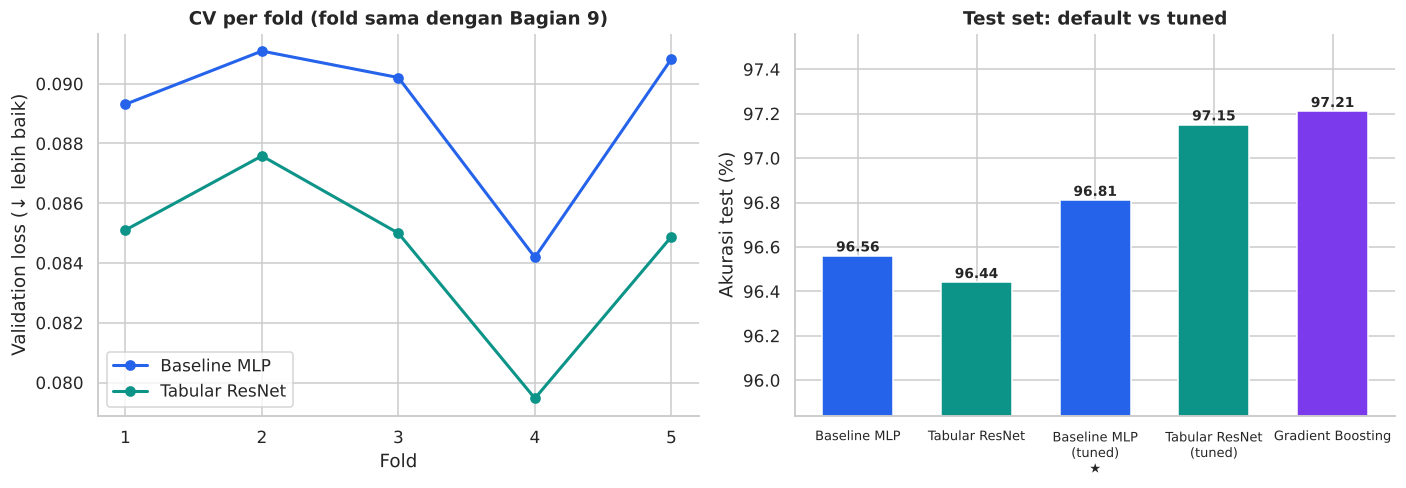


### 🔎 Ringkasan Eksplorasi ResNet
- **CV (fold sama):** Tabular ResNet lebih baik di val-loss (Δ val-loss -0.0047 vs Baseline, lebih baik di 5/5 fold).
- **Test, resep default:** ResNet **96.44%** vs Baseline **96.56%** (-0.12 poin): praktis seri.
- **Test, sama-sama dituning:** ResNet **97.15%** (5 seed: 97.07% ± 0.13%) vs champion **96.81%** (5 seed: 96.89% ± 0.06%) → ResNet **sedikit lebih tinggi** dari champion (+0.18 poin pada rerata 5 seed; +0.34 pada satu kali jalan). Gradient Boosting: **97.21%**.
- **Ukuran model:** ResNet tuned 23,841 parameter (champion: 36.545), jadi keuntungannya bukan karena model lebih besar.
- **Cara membaca:** ini eksplorasi di luar silabus. Champion untuk kesimpulan utama tetap **Baseline MLP**, dipilih lebih dulu dengan aturan 1-SE pada tiga arsitektur silabus. Di antara arsitektur silabus, yang sederhana menang; *skip connection* memberi tambahan **kecil** (+0.18 poin pada rerata 5 seed) dan hasilnya tetap dalam kisaran Gradient Boosting. Catatan keadilan: ResNet diberi anggaran tuning yang sama dengan champion; optimum tuning di tepi grid ditandai di atas.


In [ ]:
# --- 14b.3  Evaluasi test (sekali untuk model baru) + stabilitas seed ---
xt_rows = []
m = build_resnet(D.dim)
m, h, be, dt = fit(m, D.Xtr, D.ytr, D.Xva, D.yva)
xt_rows.append(dict(model="Tabular ResNet", params=n_params(m), **{f"test_{k}": v for k, v in evaluate(m, D.Xte, D.yte).items()}))
m = build_resnet(D.dim, width=X_W)
m, h, be, dt = fit(m, D.Xtr, D.ytr, D.Xva, D.yva, lr=X_OPT_LR, wd=X_WD, optimizer=X_OPT)
xt_rows.append(dict(model="Tabular ResNet (tuned)", params=n_params(m), **{f"test_{k}": v for k, v in evaluate(m, D.Xte, D.yte).items()}))
xs_rows = []
for s in range(N_SEEDS):
    m = build_resnet(D.dim, seed=SEED + 100 + s, width=X_W)
    m, _, be, _ = fit(m, D.Xtr, D.ytr, D.Xva, D.yva, lr=X_OPT_LR, wd=X_WD, optimizer=X_OPT, seed=SEED + 100 + s, track_train=False)
    xs_rows.append(evaluate(m, D.Xte, D.yte)["accuracy"])
X_SEED = (float(np.mean(xs_rows)), float(np.std(xs_rows, ddof=1)))

cmp_rows = [("Baseline MLP", REF["Baseline MLP"]), ("Tabular ResNet", {k: xt_rows[0][f"test_{k}"] for k in ["accuracy", "f1", "roc_auc", "loss"]}),
            ("Baseline MLP (tuned) ★ champion", REF["Baseline MLP (tuned)"]),
            ("Tabular ResNet (tuned)", {k: xt_rows[1][f"test_{k}"] for k in ["accuracy", "f1", "roc_auc", "loss"]}),
            ("Gradient Boosting", REF["Gradient Boosting"])]
xcmp = pd.DataFrame({n: v for n, v in cmp_rows}).T
display(xcmp.style.format("{:.4f}").background_gradient(subset=["accuracy"], cmap="Greens"))
xcmp.to_csv(OUT_DIR / "ekstensi_resnet_test.csv")
print(f"Stabilitas 5 seed — ResNet tuned: {X_SEED[0]*100:.2f}% ± {X_SEED[1]*100:.2f}%   |   champion Baseline: {REF_SEED[0]*100:.2f}% ± {REF_SEED[1]*100:.2f}%")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
for n, col in [("Baseline MLP", C["blue"]), ("Tabular ResNet", C["teal"])]:
    axes[0].plot(xpiv.index, xpiv[n], "o-", color=col, label=n, lw=2)
axes[0].set_xticks(xpiv.index); axes[0].set_xlabel("Fold"); axes[0].set_ylabel("Validation loss (↓ lebih baik)")
axes[0].set_title("CV per fold (fold sama dengan Bagian 9)"); axes[0].legend()
cols = [C["blue"], C["teal"], C["blue"], C["teal"], C["purple"]]
vals = xcmp["accuracy"].values * 100
bars = axes[1].bar(range(len(xcmp)), vals, color=cols, width=.6)
for bb, v in zip(bars, vals): axes[1].text(bb.get_x()+bb.get_width()/2, v+.02, f"{v:.2f}", ha="center", fontweight="bold", fontsize=9)
axes[1].set_xticks(range(len(xcmp))); axes[1].set_xticklabels([i.replace(" (tuned)", "\n(tuned)").replace(" ★ champion", "\n★") for i in xcmp.index], fontsize=8.5)
axes[1].set_ylim(vals.min()-.6, vals.max()+.35); axes[1].set_ylabel("Akurasi test (%)"); axes[1].set_title("Test set: default vs tuned")
savefig("11_ekstensi_resnet"); plt.show()

# ---- Ringkasan dinamis (angka selalu sinkron dengan output di atas) ----
r_def, r_tun = xt_rows[0]["test_accuracy"], xt_rows[1]["test_accuracy"]
b_def, b_tun, g_acc = REF["Baseline MLP"]["accuracy"], REF["Baseline MLP (tuned)"]["accuracy"], REF["Gradient Boosting"]["accuracy"]
d_tun  = (r_tun - b_tun) * 100                      # satu kali jalan
d_seed = (X_SEED[0] - REF_SEED[0]) * 100            # rerata 5 seed: ukuran yang lebih jujur
cv_say = ("lebih baik di val-loss" if (X_WINS >= CV_FOLDS-1 and X_DLOSS < 0) else ("lebih buruk di val-loss" if (X_WINS <= 1 and X_DLOSS > 0) else "tidak konsisten di val-loss"))
if abs(d_seed) < 0.10: acc_say = "**setara** dengan champion"
elif d_seed > 0:       acc_say = f"**sedikit lebih tinggi** dari champion (+{d_seed:.2f} poin pada rerata 5 seed; +{d_tun:.2f} pada satu kali jalan)"
else:                  acc_say = f"**lebih rendah** dari champion ({d_seed:.2f} poin pada rerata 5 seed)"
EXT = dict(cv_wins=X_WINS, cv_dloss=X_DLOSS, res_default=r_def, res_tuned=r_tun, base_tuned=b_tun, gb=g_acc, d_seed=d_seed)
display(Markdown(f'''
### 🔎 Ringkasan Eksplorasi ResNet
- **CV (fold sama):** Tabular ResNet {cv_say} (Δ val-loss {X_DLOSS:+.4f} vs Baseline, lebih baik di {X_WINS}/{CV_FOLDS} fold).
- **Test, resep default:** ResNet **{r_def*100:.2f}%** vs Baseline **{b_def*100:.2f}%** ({(r_def-b_def)*100:+.2f} poin): praktis seri.
- **Test, sama-sama dituning:** ResNet **{r_tun*100:.2f}%** (5 seed: {X_SEED[0]*100:.2f}% ± {X_SEED[1]*100:.2f}%) vs champion **{b_tun*100:.2f}%** (5 seed: {REF_SEED[0]*100:.2f}% ± {REF_SEED[1]*100:.2f}%) → ResNet {acc_say}. Gradient Boosting: **{g_acc*100:.2f}%**.
- **Ukuran model:** ResNet tuned {xt_rows[1]["params"]:,} parameter (champion: 36.545), jadi keuntungannya bukan karena model lebih besar.
- **Cara membaca:** ini eksplorasi di luar silabus. Champion untuk kesimpulan utama tetap **{CHAMPION}**, dipilih lebih dulu dengan aturan 1-SE pada tiga arsitektur silabus. Di antara arsitektur silabus, yang sederhana menang; *skip connection* memberi tambahan **kecil** ({d_seed:+.2f} poin pada rerata 5 seed) dan hasilnya tetap dalam kisaran Gradient Boosting. Catatan keadilan: ResNet diberi anggaran tuning yang sama dengan champion; optimum tuning di tepi grid ditandai di atas.
'''))

---
## 15. Kesimpulan dan Keterbatasan

In [25]:
ch = final.loc[CH_NAME]; hgb = final.loc["Gradient Boosting (HistGB)"]; lr_ = final.loc["Logistic Regression"]
A_, B_, C_, D_ = abl.iloc[0], abl.iloc[1], abl.iloc[2], abl.iloc[3]
dflt = final.loc[CHAMPION]                       # champion dengan resep default (belum dituning)
t3 = lambda s: ", ".join(f"`{c}`" for c in s.feature.head(5))

# Ringkasan CV per arsitektur terhadap Baseline (dinamis)
cv_lines = []
for n in ARCHS:
    if n == "Baseline MLP": continue
    d_loss = (piv[n] - piv["Baseline MLP"]).mean(); wins = int((piv[n] < piv["Baseline MLP"]).sum())
    verdict = "lebih baik" if wins >= CV_FOLDS - 1 and d_loss < 0 else ("lebih buruk" if wins <= 1 and d_loss > 0 else "tidak konsisten")
    cv_lines.append(f"{n}: Δ val-loss {d_loss:+.4f} vs Baseline, menang di {wins}/{CV_FOLDS} fold → **{verdict}**")
cv_txt = "; ".join(cv_lines)
acc_rng = agg["accuracy"].max() - agg["accuracy"].min()
tune_gain = (ch.test_accuracy - dflt.test_accuracy) * 100

txt = f'''
### ✅ Temuan Utama
1. **Prediksi sangat akurat tanpa kebocoran neraca.** Champion (**{CHAMPION}**, hasil tuning) mencapai **akurasi {ch.test_accuracy*100:.2f}%**, F1 **{ch.test_f1:.4f}**, ROC-AUC **{ch.test_roc_auc:.4f}** pada 10.000 data *test* yang tidak dipakai memilih apa pun. Stabilitas antar-seed: akurasi {SEED_STATS.loc['mean','test_acc']*100:.2f}% ± {SEED_STATS.loc['std','test_acc']*100:.2f}%.
2. **Perbandingan arsitektur (5-fold CV).** Val-loss rata-rata: Baseline **{agg.loc['Baseline MLP','val_loss']:.4f}**, Deep Regularized MLP **{agg.loc['Deep Regularized MLP','val_loss']:.4f}**, Wide Regularized MLP **{agg.loc['Wide Regularized MLP','val_loss']:.4f}**. {cv_txt}. Selisih akurasi antar-arsitektur hanya **{acc_rng*100:.2f} poin** — jadi perbedaannya nyata pada log-loss, tetapi **kecil secara praktis**. Dengan aturan 1-SE, champion = **{CHAMPION}**.
3. **Tuning membantu.** Champion default → tuned: akurasi test {dflt.test_accuracy*100:.2f}% → {ch.test_accuracy*100:.2f}% ({tune_gain:+.2f} poin), test loss {dflt.test_loss:.4f} → {ch.test_loss:.4f}. *Catatan keadilan:* hanya champion yang dituning; pembanding lain memakai resep default.
4. **Deep learning vs baseline klasik.** Gradient Boosting: akurasi **{hgb.test_accuracy*100:.2f}%** (AUC {hgb.test_roc_auc:.4f}); Logistic Regression: **{lr_.test_accuracy*100:.2f}%** (AUC {lr_.test_roc_auc:.4f}); champion NN: **{ch.test_accuracy*100:.2f}%** (AUC {ch.test_roc_auc:.4f}). {"Gradient Boosting setara/lebih baik dari neural network pada data tabular ini — manfaat deep learning di sini terbatas." if hgb.test_accuracy >= ch.test_accuracy - 0.003 else "Neural network unggul jelas dari baseline klasik."}
5. **Dampak leakage terukur.** Set A (komponen neraca dipakai): akurasi **{A_.test_acc*100:.2f}%** vs Set B (bersih): **{B_.test_acc*100:.2f}%** — selisih **{(A_.test_acc-B_.test_acc)*100:+.2f} poin** (AUC {A_.test_auc:.4f} vs {B_.test_auc:.4f}). Selisihnya terlihat modest karena arus uang (pendapatan, rasio investasi) sudah sangat informatif, tetapi komponen neraca tetap tidak sah dipakai: ia memuat kekayaan yang menjadi definisi target.
6. **Tanpa arus uang, prediksi turun tajam namun tetap bermakna.** Set C (kebiasaan + psikologi + karier + demografi): akurasi **{C_.test_acc*100:.2f}%** (AUC {C_.test_auc:.4f}); Set D (tanpa indeks komposit): **{D_.test_acc*100:.2f}%** (AUC {D_.test_auc:.4f}). Pembanding: menebak kelas mayoritas = 57,5%. Artinya **nominal uang (pendapatan, tabungan, rasio investasi) jauh lebih menentukan daripada kebiasaan murni**.
7. **Overfitting.** Bobot terbaik di-*restore* dari epoch dengan val-loss terendah. Gap akurasi train–val pada epoch terbaik: Baseline {gap.loc['Baseline MLP','Gap acc (train−val)']*100:+.2f} poin, Deep MLP {gap.loc['Deep Regularized MLP','Gap acc (train−val)']*100:+.2f}, Wide MLP {gap.loc['Wide Regularized MLP','Gap acc (train−val)']*100:+.2f}. Model cepat menghafal data latih (akurasi train → ~99%), sehingga early stopping sangat penting.

### 🔑 Faktor yang Paling Menentukan (permutation importance, 5 teratas)
- **Set B (semua fitur sah):** {t3(imp_B)}
- **Set C (tanpa arus uang):** {t3(imp_C)}
- **Set D (tanpa arus uang & indeks komposit):** {t3(imp_D)}
'''
display(Markdown(txt))



### ✅ Temuan Utama
1. **Prediksi sangat akurat tanpa kebocoran neraca.** Champion (**Baseline MLP**, hasil tuning) mencapai **akurasi 96.81%**, F1 **0.9624**, ROC-AUC **0.9970** pada 10.000 data *test* yang tidak dipakai memilih apa pun. Stabilitas antar-seed: akurasi 96.89% ± 0.06%.
2. **Perbandingan arsitektur (5-fold CV).** Val-loss rata-rata: Baseline **0.0894**, Deep Regularized MLP **0.0932**, Wide Regularized MLP **0.0976**. Deep Regularized MLP: Δ val-loss +0.0039 vs Baseline, menang di 0/5 fold → **lebih buruk**; Wide Regularized MLP: Δ val-loss +0.0082 vs Baseline, menang di 0/5 fold → **lebih buruk**. Selisih akurasi antar-arsitektur hanya **0.45 poin** — jadi perbedaannya nyata pada log-loss, tetapi **kecil secara praktis**. Dengan aturan 1-SE, champion = **Baseline MLP**.
3. **Tuning membantu.** Champion default → tuned: akurasi test 96.56% → 96.81% (+0.25 poin), test loss 0.0814 → 0.0706. *Catatan keadilan:* hanya champion yang dituning; pembanding lain memakai resep default.
4. **Deep learning vs baseline klasik.** Gradient Boosting: akurasi **97.21%** (AUC 0.9974); Logistic Regression: **95.22%** (AUC 0.9906); champion NN: **96.81%** (AUC 0.9970). Gradient Boosting setara/lebih baik dari neural network pada data tabular ini — manfaat deep learning di sini terbatas.
5. **Dampak leakage terukur.** Set A (komponen neraca dipakai): akurasi **98.86%** vs Set B (bersih): **96.81%** — selisih **+2.05 poin** (AUC 0.9995 vs 0.9970). Selisihnya terlihat modest karena arus uang (pendapatan, rasio investasi) sudah sangat informatif, tetapi komponen neraca tetap tidak sah dipakai: ia memuat kekayaan yang menjadi definisi target.
6. **Tanpa arus uang, prediksi turun tajam namun tetap bermakna.** Set C (kebiasaan + psikologi + karier + demografi): akurasi **76.31%** (AUC 0.8406); Set D (tanpa indeks komposit): **74.07%** (AUC 0.8139). Pembanding: menebak kelas mayoritas = 57,5%. Artinya **nominal uang (pendapatan, tabungan, rasio investasi) jauh lebih menentukan daripada kebiasaan murni**.
7. **Overfitting.** Bobot terbaik di-*restore* dari epoch dengan val-loss terendah. Gap akurasi train–val pada epoch terbaik: Baseline +1.90 poin, Deep MLP +3.12, Wide MLP +2.76. Model cepat menghafal data latih (akurasi train → ~99%), sehingga early stopping sangat penting.

### 🔑 Faktor yang Paling Menentukan (permutation importance, 5 teratas)
- **Set B (semua fitur sah):** `investment_income_ratio`, `passive_income_ratio`, `income_percentile`, `housing_cost_ratio`, `debt_to_income_ratio`
- **Set C (tanpa arus uang):** `wealth_building_index`, `occupation_category`, `country`, `age`, `invests_regularly`
- **Set D (tanpa arus uang & indeks komposit):** `occupation_category`, `country`, `income_diversification_score`, `age`, `years_of_experience`


### Ringkasan
**Kami membandingkan lebar vs kedalaman: yang sederhana menang, dan boosting setara atau sedikit lebih baik.**
Di antara tiga arsitektur silabus, Baseline MLP unggul di 5-fold CV dan dipilih lewat aturan 1-SE. Gradient Boosting setara atau sedikit lebih baik di test. Tabular ResNet (Bagian 14b) hanya menambah sedikit (sekitar +0,2 poin pada rerata 5 seed) dan tidak mengubah champion maupun angka utama.

### Keterbatasan
- **Data sintetis.** Polanya dibentuk aturan pembangkit data, jadi temuan belum tentu berlaku di dunia nyata.
- **Bukan kausal.** Tabungan tinggi berkaitan dengan status jutawan, tapi tidak berarti menabung menyebabkan kaya (bisa juga sebaliknya).
- **Arus uang di Set B tetap dekat dengan hasil akhir** (pendapatan tinggi, kekayaan tinggi). Set C/D disediakan sebagai batas bawah.
- **Set C/D bukan kebiasaan murni.** Masih ada demografi dan karier (`country`, `occupation_category`, `age`), jadi bacalah sebagai perilaku plus latar belakang.
- **Ukuran leakage Set A hanya perkiraan**, karena total aset tidak sepenuhnya bisa direkonstruksi dari 11 komponen yang ada.
- **Satu split tetap** untuk tuning dan evaluasi akhir. CV dan uji multi-seed mengurangi ketergantungan itu tapi tidak menghilangkannya. Early stopping di fold CV membuat skor CV sedikit optimistis, dengan efek yang sama untuk semua arsitektur.
- Imputasi median untuk kolom yang kosong secara struktural (mis. `business_failure_count` untuk non-pengusaha) menyembunyikan informasi "tidak berlaku".

### Saran lanjutan
1. Tambah missing indicator untuk kolom yang kosong secara struktural.
2. Coba model tabular lain (TabNet, FT-Transformer) atau ensembling NN + Gradient Boosting.
3. Pakai SHAP untuk penjelasan per individu.
4. Kalibrasi probabilitas (Platt/isotonic) bila dipakai untuk keputusan.
5. Coba regresi `net_worth` (log) sebagai pelengkap.

---
### Menyimpan Artefak
Model champion, preprocessor, dan konfigurasi disimpan supaya bisa dipakai ulang tanpa melatih ulang.

In [26]:
torch.save({"state_dict": CHAMP_MODEL.state_dict(), "arch": CHAMPION, "kwargs": {**DEFAULT_KW[CHAMPION], **BEST_KW}, "input_dim": D.dim},
           OUT_DIR / "champion_model.pt")
joblib.dump({"preprocessor": D.prep, "feature_cols": FEATURES_MAIN, "num_cols": D.num, "cat_cols": D.cat}, OUT_DIR / "preprocessor_setB.joblib")
json.dump({"champion": CHAMPION, "lr": BEST_OPT_LR, "weight_decay": BEST_WD, "optimizer": BEST_OPT, "capacity": {k: (v if not isinstance(v, np.generic) else v.item()) for k, v in BEST_KW.items()},
           "threshold_f1_val": THR, "seed": SEED, "split": "80/10/10 stratified", "n_features_set_B": len(FEATURES_MAIN)},
          open(OUT_DIR / "config_final.json", "w"), indent=2)
print("Tersimpan di folder 'outputs/':", sorted(p.name for p in OUT_DIR.iterdir()))
print("Gambar di folder 'figures/'   :", sorted(p.name for p in FIG_DIR.iterdir()))

Tersimpan di folder 'outputs/': ['champion_model.pt', 'config_final.json', 'cv_results_per_fold.csv', 'final_test_results.csv', 'permutation_importance_setB.csv', 'permutation_importance_setC.csv', 'permutation_importance_setD.csv', 'preprocessor_setB.joblib']
Gambar di folder 'figures/'   : ['01_target_dan_missing.png', '02_distribusi_fitur.png', '03_audit_leakage.png', '04_cv_benchmark.png', '05_tuning.png', '06_ablation_fitur.png', '07_kurva_belajar.png', '08_cm_roc_pr.png', '09_kalibrasi_threshold.png', '10_permutation_importance.png']


---
## 16. Repositori & Referensi

**Repositori kode:** `https://github.com/Kenzi-GIT/Dip-Lerning`

**Referensi**
1. Goodfellow, I., Bengio, Y., & Courville, A. (2016). *Deep Learning*. MIT Press.
2. Ioffe, S., & Szegedy, C. (2015). *Batch Normalization: Accelerating Deep Network Training by Reducing Internal Covariate Shift*. ICML.
3. Srivastava, N., Hinton, G., Krizhevsky, A., Sutskever, I., & Salakhutdinov, R. (2014). *Dropout: A Simple Way to Prevent Neural Networks from Overfitting*. JMLR 15(1).
4. Loshchilov, I., & Hutter, F. (2019). *Decoupled Weight Decay Regularization (AdamW)*. ICLR.
5. Breiman, L. (2001). *Random Forests* (permutation importance). Machine Learning, 45(1).
6. Hastie, T., Tibshirani, R., & Friedman, J. (2009). *The Elements of Statistical Learning* (aturan satu-standar-error), Springer.
7. Afiahayati. (2026). *Slide Perkuliahan Pembelajaran Mesin Mendalam*. FMIPA UGM.
